# Straight Rows: development episodes and extended checks

Explores the 12 labelled development episodes in `starter/data` (all data in the package is simulated). Three tractors,
1 Hz telemetry for 72 h, SDA context (Kp, Dst, S4, advisories, RFI reports) and `labels/train_episodes.json`.

Things that differ from a "one tractor, one cause" picture, and that every section below accounts for:

* **Episodes list their affected tractors** (all three, a pair, or one), and they can **overlap** each other
  (TRN-05 and TRN-08 sit inside the second storm episode, so their "30 min before" baseline is already degraded).
* **Durations span 17 s to 5 h** (multipath is a 17 s blip), so plot margins and time units adapt to the episode.
* **Machines work only 11:00Z-03:00Z** and are parked otherwise; parked rows are much noisier and are not scored.
* **Fix state has five levels, the correction link is a boolean**, and RFI reports carry a position and an uncertainty
  ellipse but only one timestamp (when the report arrived, 10-30 min after the event).

In [1]:
import json
import os
import sys
from datetime import timezone
from functools import lru_cache
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
try:
    from IPython.display import display
except ImportError:              # plain python / a kernel without IPython: fall back to print
    display = print

pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 80)


def find_data():
    """starter/data (or data/) in the working directory or any parent; set STRAIGHTROWS_DATA to override."""
    env = os.environ.get("STRAIGHTROWS_DATA")
    cands = [Path(env)] if env else [c for p in [Path.cwd(), *Path.cwd().parents] for c in (p / "starter" / "data", p / "data")]
    for cand in cands:
        if (cand / "farm" / "tractor_telemetry.csv.gz").is_file():
            return cand
    raise FileNotFoundError(f"farm/tractor_telemetry.csv.gz not found under starter/data or data above {Path.cwd()} "
                            "(open the notebook from inside the repo, or set STRAIGHTROWS_DATA to the data folder)")


DATA = find_data()
EVAL_START, EVAL_END = pd.Timestamp("2026-05-06T00:00:00Z"), pd.Timestamp("2026-05-07T00:00:00Z")
SEC = pd.Timedelta("1s")
PAD = pd.Timedelta("30min")     # baseline length before onset, and the default plot margin

# ---- telemetry -----------------------------------------------------------------------------------------------------
FIX_ORDER = ["RTK_FIXED", "RTK_FLOAT", "DGPS", "AUTONOMOUS", "NO_FIX"]          # best -> worst
tel = pd.read_csv(DATA / "farm" / "tractor_telemetry.csv.gz")
ISO = {"format": "ISO8601"} if int(pd.__version__.split(".")[0]) >= 2 else {}   # mixed fractional seconds need pandas >= 2
tel["ts"] = pd.to_datetime(tel["ts"], utc=True, **ISO)
tel["fix_rank"] = tel["fix_state"].map({s: i for i, s in enumerate(FIX_ORDER)})
tel["link_down"] = (~tel["base_link_ok"]).astype(int)
tel["moving"] = tel["speed_mps"] > 0
tel["cn0_gap"] = tel["mean_cn0_dbhz"] - tel["min_cn0_dbhz"]
for s in FIX_ORDER:
    tel[f"fix={s}"] = (tel["fix_state"] == s).astype(float)
tel = tel.sort_values(["tractor_id", "ts"]).reset_index(drop=True)
by = {t: g.set_index("ts") for t, g in tel.groupby("tractor_id")}          # one frame per tractor, indexed by time
TR = list(by)

# ---- SDA feeds -----------------------------------------------------------------------------------------------------
def _json(name):
    return json.loads((DATA / "sda" / name).read_text())

kp = pd.DataFrame(_json("sgi_indices.json")["kp"])
dst = pd.DataFrame(_json("sgi_indices.json")["dst"]).rename(columns={"dst_nT": "dst"})
s4 = pd.DataFrame(_json("scintillation_series.json")["series"])
adv = pd.DataFrame(_json("constellation_advisories.json")["advisories"])
rfi = pd.DataFrame(_json("rfi_reports.json")["reports"])
for df in (kp, dst, s4, adv, rfi):
    df["ts"] = pd.to_datetime(df["ts"], utc=True, **ISO)      # RFI times mix with / without fractional seconds

# ---- labelled development episodes ---------------------------------------------------------------------------------
eps = json.loads((DATA / "labels" / "train_episodes.json").read_text())["episodes"]
for i, e in enumerate(eps):
    e["i"], e["trs"] = i, list(e["tractors"])
    e["s"], e["e"] = pd.Timestamp(e["start"]), pd.Timestamp(e["end"])
    e["dur_s"] = (e["e"] - e["s"]).total_seconds()
    e["min"] = e["dur_s"] / 60

CLASS_LIST = ["SPACE_WEATHER", "JAMMING", "SPOOFING", "EQUIPMENT_FAULT", "MULTIPATH"]
CLASSES = [c for c in CLASS_LIST if any(e["class"] == c for e in eps)]
COLOR = {"SPACE_WEATHER": "goldenrod", "JAMMING": "crimson", "SPOOFING": "purple", "EQUIPMENT_FAULT": "teal", "MULTIPATH": "saddlebrown"}
TCOL = {"T1": "tab:blue", "T2": "tab:orange", "T3": "tab:green"}
STATE_Y = {s: i for i, s in enumerate(FIX_ORDER)}


def fmt_dur(sec):
    return f"{sec:.0f}s" if sec < 120 else (f"{sec / 60:.0f}m" if sec < 7200 else f"{sec / 3600:.1f}h")


def seg(tr, a, b):
    """Rows of one tractor in [a, b)."""
    return by[tr].loc[a: b - SEC]


def margin(e):
    return PAD if e["dur_s"] >= 600 else pd.Timedelta("3min")


def near(df, col, t):
    return df.loc[(df["ts"] - t).abs().idxmin(), col]


def overlapping(e, back=PAD):
    """Ids of the other labelled episodes that overlap this one or its baseline window."""
    return [o["id"] for o in eps if o is not e and o["s"] < e["e"] and e["s"] - back < o["e"]]


print(f"data: {DATA}  | python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}")
print(f"telemetry: {len(tel):,} rows, tractors {TR}, {tel.ts.min():%Y-%m-%d %H:%M} -> {tel.ts.max():%Y-%m-%d %H:%M} UTC, "
      f"moving {tel.moving.mean():.0%} of the time")
print(f"labelled episodes: {len(eps)} {pd.Series([e['class'] for e in eps]).value_counts().to_dict()}")
print(f"SDA: {len(kp)} Kp, {len(dst)} Dst, {len(s4)} S4, {len(adv)} advisories, {len(rfi)} RFI reports")

data: /home/dylan/dev/bluestaq-hackathon/starter/data  | python 3.12.3, pandas 2.3.3, numpy 2.3.3
telemetry: 777,600 rows, tractors ['T1', 'T2', 'T3'], 2026-05-04 00:00 -> 2026-05-06 23:59 UTC, moving 67% of the time
labelled episodes: 12 {'JAMMING': 3, 'SPOOFING': 3, 'SPACE_WEATHER': 2, 'EQUIPMENT_FAULT': 2, 'MULTIPATH': 2}
SDA: 24 Kp, 72 Dst, 288 S4, 2 advisories, 4 RFI reports


## The 72 hours at a glance

5-minute fleet signal health and guidance error per tractor, against Kp / Dst and the S4 scintillation proxy, with the
labelled episodes shaded by class. The dashed line is the start of the unlabelled evaluation window.

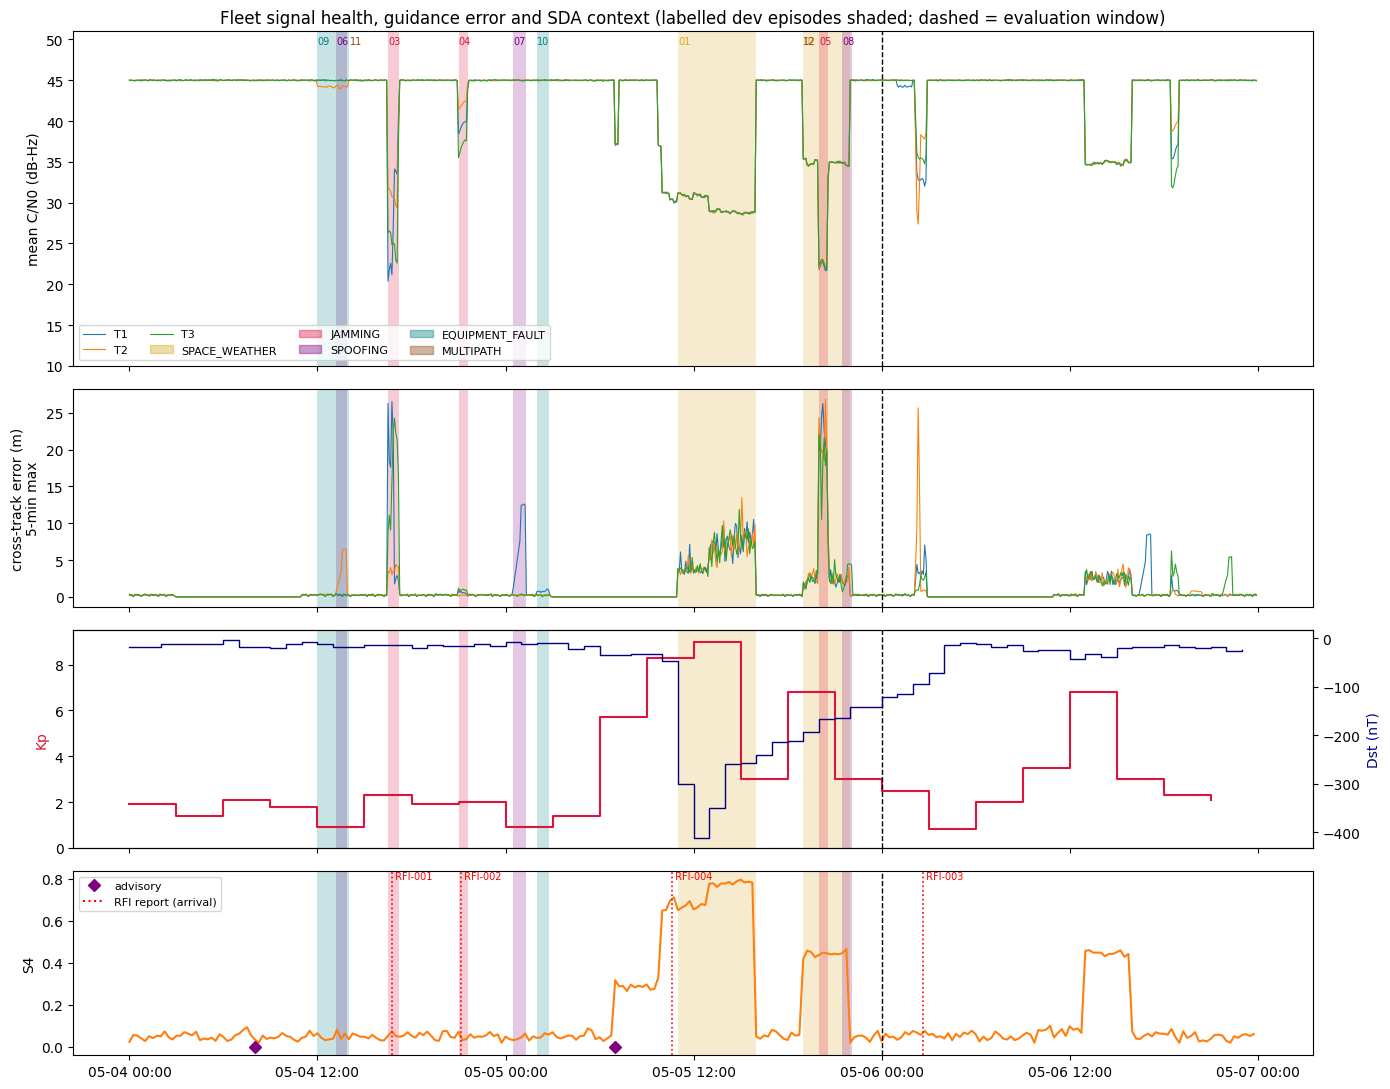

In [2]:
g5 = tel.set_index("ts").groupby("tractor_id")
cn0_5 = g5["mean_cn0_dbhz"].resample("5min").mean().unstack(0)
xte_5 = g5["cross_track_error_m"].resample("5min").max().unstack(0)
fig, ax = plt.subplots(4, 1, figsize=(14, 11), sharex=True, gridspec_kw={"height_ratios": [2, 1.3, 1.3, 1.1]})
for t in TR:
    ax[0].plot(cn0_5.index, cn0_5[t], lw=0.8, color=TCOL[t], label=t)
    ax[1].plot(xte_5.index, xte_5[t], lw=0.8, color=TCOL[t])
ax[0].set_ylabel("mean C/N0 (dB-Hz)"); ax[0].legend(loc="lower left", ncol=3)
ax[1].set_ylabel("cross-track error (m)\n5-min max")
ax[2].step(kp["ts"], kp["kp"], where="post", color="crimson"); ax[2].set_ylabel("Kp", color="crimson"); ax[2].set_ylim(0, 9.5)
d2 = ax[2].twinx(); d2.step(dst["ts"], dst["dst"], where="post", color="navy", lw=1); d2.set_ylabel("Dst (nT)", color="navy")
ax[3].plot(s4["ts"], s4["s4"], color="C1"); ax[3].set_ylabel("S4")
for _, r in rfi.iterrows():
    ax[3].axvline(r["ts"], color="red", ls=":", lw=1.2)
    ax[3].text(r["ts"], ax[3].get_ylim()[1], f" {r['id']}", color="red", fontsize=7, va="top")
for _, r in adv.iterrows():
    ax[3].plot(r["ts"], 0, "D", color="purple", ms=6)
ax[3].plot([], [], "D", color="purple", label="advisory"); ax[3].plot([], [], "r:", label="RFI report (arrival)"); ax[3].legend(loc="upper left", fontsize=8)
for a in ax:
    for e in eps:
        a.axvspan(e["s"], e["e"], color=COLOR[e["class"]], alpha=0.22 if e["dur_s"] > 120 else 0.9, lw=0)
    a.axvline(EVAL_START, color="k", ls="--", lw=1)
for e in eps:
    ax[0].text(e["s"], 49.5, e["id"][-2:], fontsize=7, color=COLOR[e["class"]], ha="left")
ax[0].set_ylim(10, 51)
h, l = ax[0].get_legend_handles_labels()
ax[0].legend(h + [Patch(color=COLOR[c], alpha=0.4) for c in CLASSES], l + CLASSES, loc="lower left", ncol=4, fontsize=8)
ax[3].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=timezone.utc))
ax[0].set_title("Fleet signal health, guidance error and SDA context (labelled dev episodes shaded; dashed = evaluation window)")
fig.tight_layout(); plt.show()

## Episode overview: each tractor inside the episode vs. the 30 min before

One row per episode **and tractor** (`*` = labelled as affected), so unaffected neighbours are visible. Each cell is
`before -> inside` (mean). `also_overlapping` lists other labelled episodes that overlap the episode or its 30 min
baseline: those baselines are not clean.

In [3]:
SIG = ["mean_cn0_dbhz", "min_cn0_dbhz", "num_sats", "cross_track_error_m", "speed_mps"]
rows = []
for e in eps:
    for t in TR:
        before, inside = seg(t, e["s"] - PAD, e["s"]), seg(t, e["s"], e["e"])
        r = {"id": e["id"], "class": e["class"], "tractor": ("*" if t in e["trs"] else " ") + t, "start": f"{e['s']:%m-%d %H:%M:%S}",
             "dur": fmt_dur(e["dur_s"])}
        for c in SIG:
            r[c.replace("_dbhz", "").replace("_mps", "").replace("_error_m", "")] = f"{before[c].mean():.1f} -> {inside[c].mean():.1f}"
        r["fix_state(mode)"] = inside.fix_state.value_counts().idxmax()
        r["link_ok"] = f"{inside.base_link_ok.mean():.0%}"
        r["also_overlapping"] = ",".join(overlapping(e))
        rows.append(r)
display(pd.DataFrame(rows).set_index(["id", "class", "tractor"]))

start   dur      mean_cn0       min_cn0      num_sats cross_track       speed fix_state(mode) link_ok      also_overlapping
id     class           tractor                                                                                                                                      
TRN-01 SPACE_WEATHER   *T1      05-05 11:00:00  5.0h  30.2 -> 29.7  21.6 -> 20.5  10.0 -> 10.0  0.0 -> 1.0  0.0 -> 4.5            DGPS    100%                      
                       *T2      05-05 11:00:00  5.0h  30.3 -> 29.7  21.9 -> 20.8  10.0 -> 10.0  0.0 -> 1.0  0.0 -> 4.5            DGPS    100%                      
                       *T3      05-05 11:00:00  5.0h  30.3 -> 29.7  21.5 -> 20.4  10.0 -> 10.0  0.0 -> 1.0  0.0 -> 4.5            DGPS    100%                      
TRN-02 SPACE_WEATHER   *T1      05-05 19:00:00  3.0h  45.0 -> 32.4  39.7 -> 24.2  12.0 -> 10.2  0.0 -> 1.0  4.5 -> 4.5       RTK_FLOAT    100%  TRN-05,TRN-08,TRN-12
                       *T2      05-05 19:00:00  3.0h  45.0 -> 32.5  40.0 -> 24.5  12.0 -> 10.3  0.0 -> 1.0  4.5 -> 4.5       RTK_FLOAT    100%  TRN-05,TRN-08,TRN-12
                       *T3      05-05 19:00:00  3.0h  45.0 -> 32.4  39.6 -> 24.1  12.0 -> 10.3  0.0 -> 1.2  4.5 -> 4.5       RTK_FLOAT    100%  TRN-05,TRN-08,TRN-12
TRN-03 JAMMING         *T1      05-04 16:30:00   42m  45.0 -> 27.1  39.7 -> 19.1   12.0 -> 6.8  0.0 -> 2.2  4.5 -> 4.5       RTK_FLOAT    100%                      
                       *T2      05-04 16:30:00   42m  45.0 -> 30.7  40.0 -> 23.5   12.0 -> 7.8  0.0 -> 0.9  4.5 -> 4.5            DGPS    100%                      
                       *T3      05-04 16:30:00   42m  45.0 -> 25.0  39.6 -> 16.6   12.0 -> 5.1  0.0 -> 2.6  4.5 -> 4.5      AUTONOMOUS    100%                      
TRN-04 JAMMING         *T1      05-04 21:00:00   36m  45.0 -> 39.4  39.7 -> 33.3  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                      
                        T2      05-04 21:00:00   36m  45.0 -> 42.1  40.0 -> 36.6  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                      
                       *T3      05-04 21:00:00   36m  45.0 -> 37.0  39.6 -> 30.3  12.0 -> 10.3  0.0 -> 0.2  4.5 -> 4.5       RTK_FLOAT    100%                      
TRN-05 JAMMING         *T1      05-05 20:00:00   36m  35.0 -> 22.2  27.2 -> 12.5   11.0 -> 7.2  0.3 -> 4.1  4.5 -> 4.5      AUTONOMOUS    100%                TRN-02
                       *T2      05-05 20:00:00   36m  35.0 -> 22.6  27.5 -> 13.2   11.0 -> 7.4  0.3 -> 3.8  4.5 -> 4.5      AUTONOMOUS    100%                TRN-02
                       *T3      05-05 20:00:00   36m  35.0 -> 22.5  27.0 -> 12.7   11.0 -> 7.4  0.3 -> 3.7  4.5 -> 4.5      AUTONOMOUS    100%                TRN-02
TRN-06 SPOOFING         T1      05-04 13:12:00   42m  45.0 -> 45.0  39.7 -> 39.7  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                TRN-09
                       *T2      05-04 13:12:00   42m  44.2 -> 44.2  36.3 -> 36.1  11.5 -> 11.6  0.0 -> 3.4  4.5 -> 4.5       RTK_FIXED    100%                TRN-09
                        T3      05-04 13:12:00   42m  45.0 -> 45.0  39.6 -> 39.6  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                TRN-09
TRN-07 SPOOFING        *T1      05-05 00:30:00   48m  45.0 -> 45.0  39.7 -> 39.7  12.0 -> 12.0  0.0 -> 6.7  4.5 -> 4.5       RTK_FIXED    100%                      
                        T2      05-05 00:30:00   48m  45.0 -> 45.0  40.0 -> 40.0  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                      
                        T3      05-05 00:30:00   48m  45.0 -> 45.0  39.6 -> 39.6  12.0 -> 12.0  0.0 -> 0.0  4.5 -> 4.5       RTK_FIXED    100%                      
TRN-08 SPOOFING         T1      05-05 21:30:00   36m  34.9 -> 36.4  27.1 -> 29.0  11.0 -> 11.2  0.3 -> 0.2  4.5 -> 4.5       RTK_FLOAT    100%                TRN-02
                        T2      05-05 21:30:00   36m  34.9 -> 36.4  27.4 -> 29.3 

## Per-episode plots

All three tractors on the same axes; the labelled ones are solid, the others dashed. Thin lines are the weakest-signal
(min C/N0). The shaded span is the labelled episode, red dotted lines are RFI reports that arrived in the window. Short
episodes get a 3 min margin instead of 30 min.

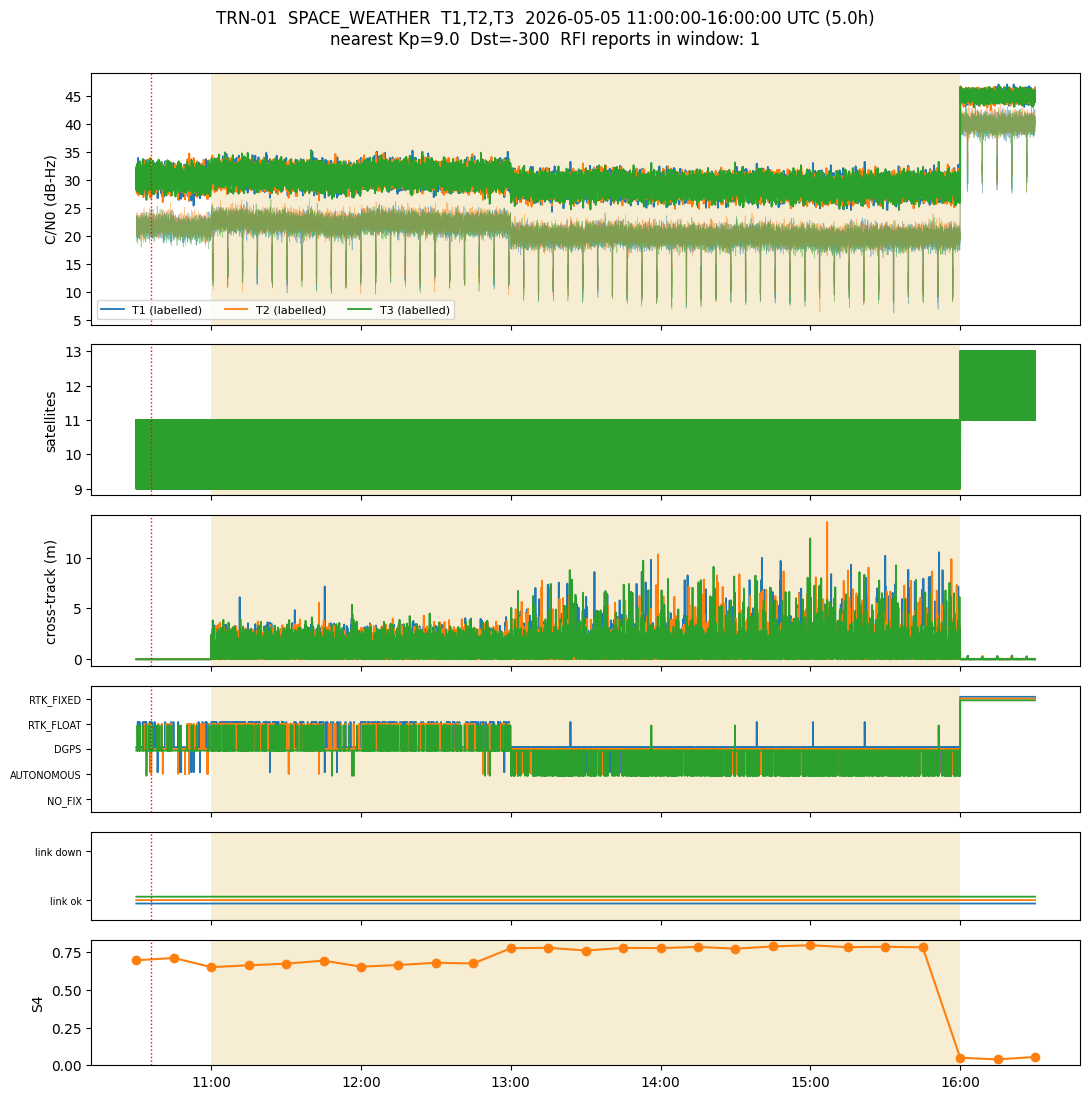

     id                        ts band  confidence  centerLat  centerLon  semiMajor_km  semiMinor_km
RFI-004 2026-05-05 10:36:00+00:00   L1        0.35      46.93     -97.25           6.0           3.5


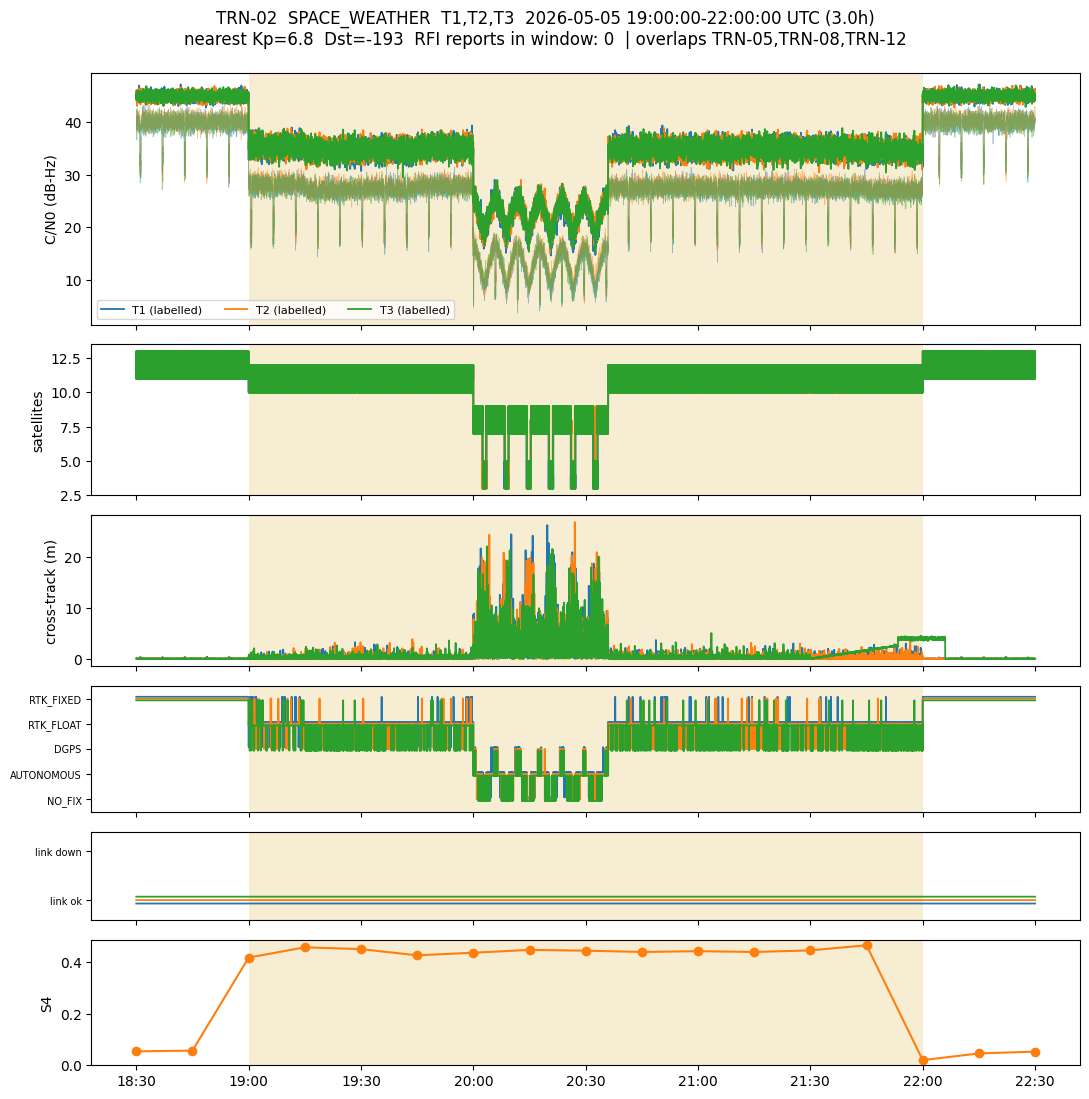

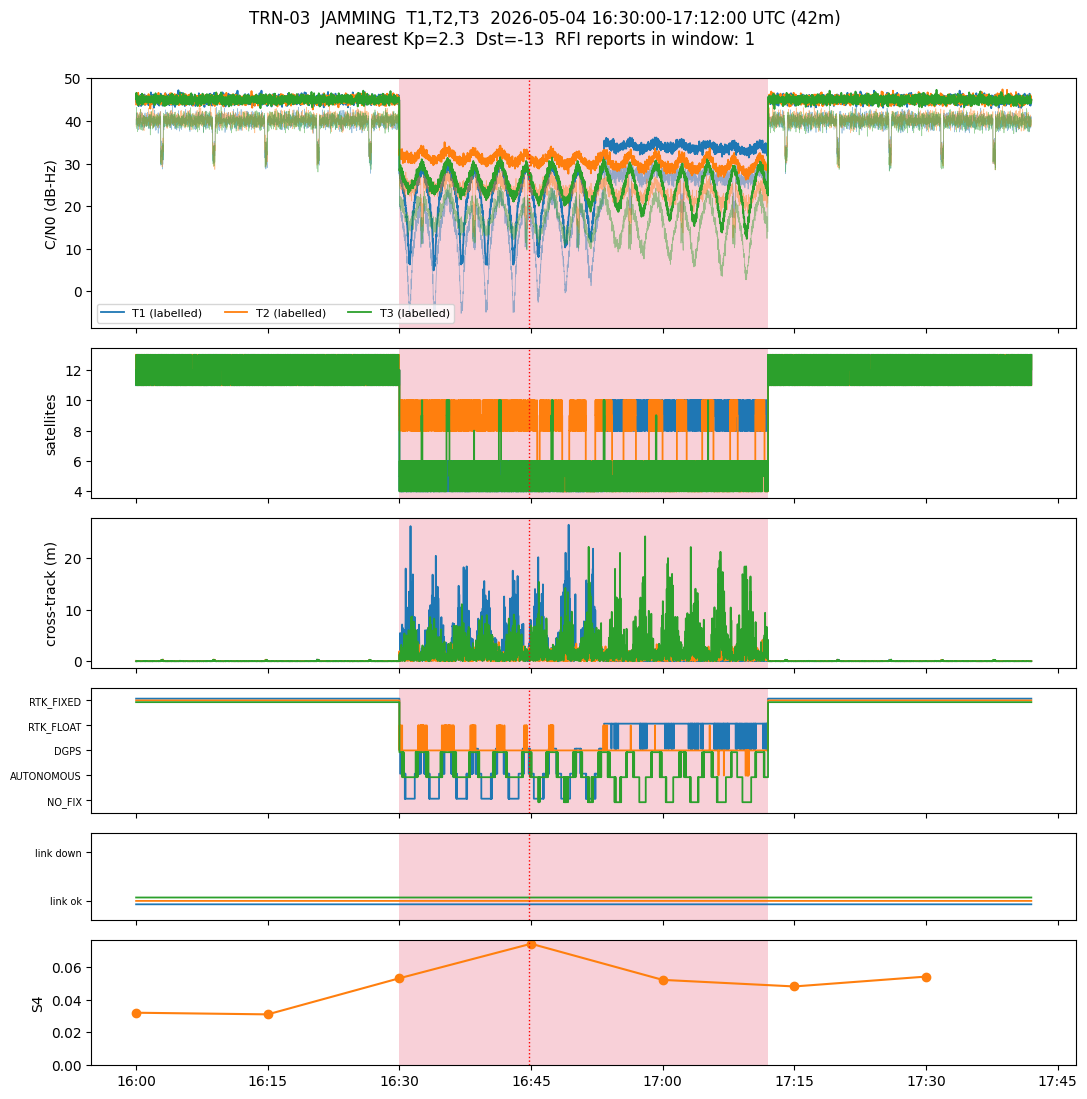

     id                               ts band  confidence  centerLat  centerLon  semiMajor_km  semiMinor_km
RFI-001 2026-05-04 16:44:48.993670+00:00   L1         0.6  46.908072 -97.192686          3.44          1.04


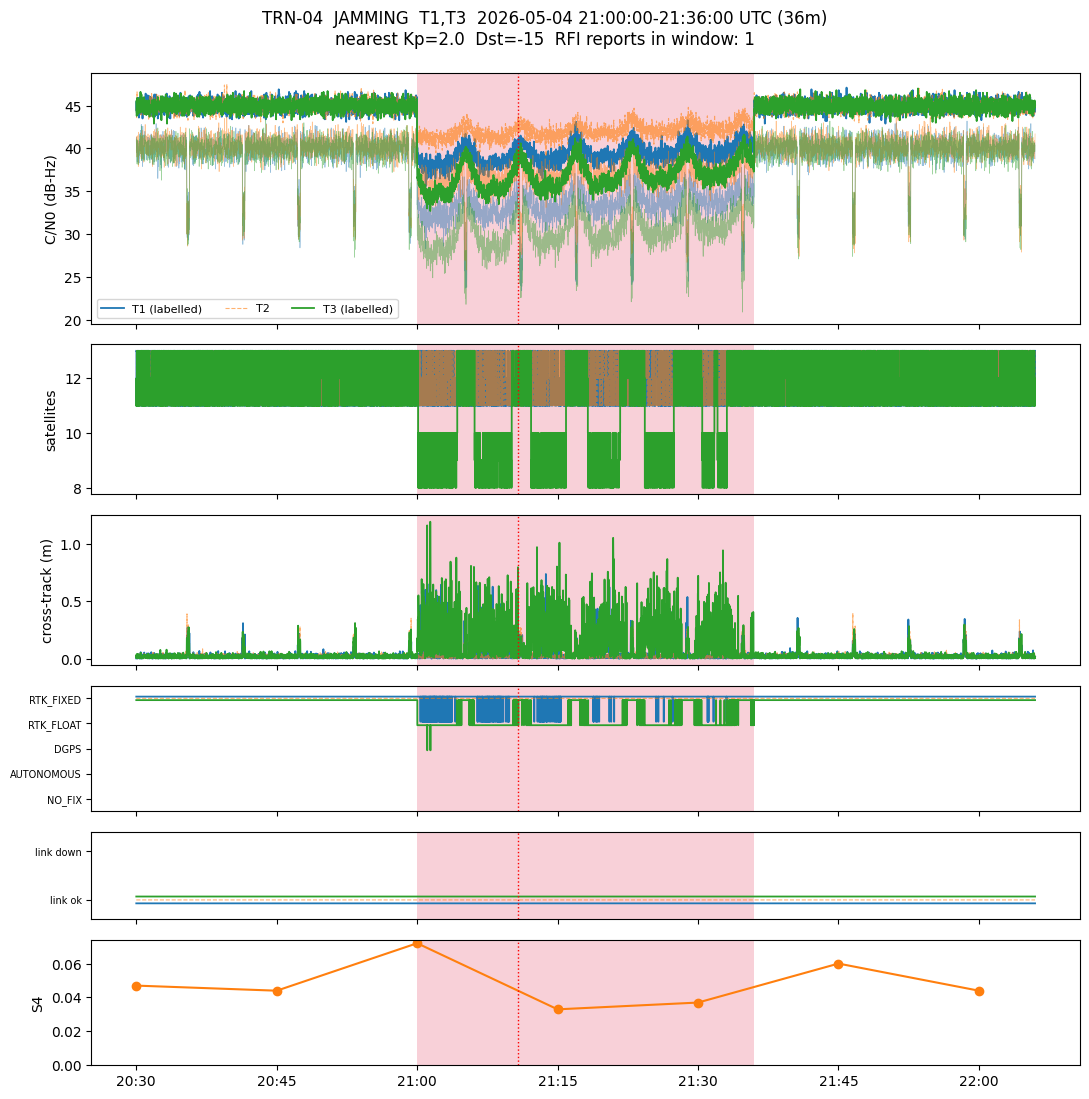

     id                               ts band  confidence  centerLat  centerLon  semiMajor_km  semiMinor_km
RFI-002 2026-05-04 21:10:43.395253+00:00   L1        0.55   46.90602 -97.212547          1.63          1.53


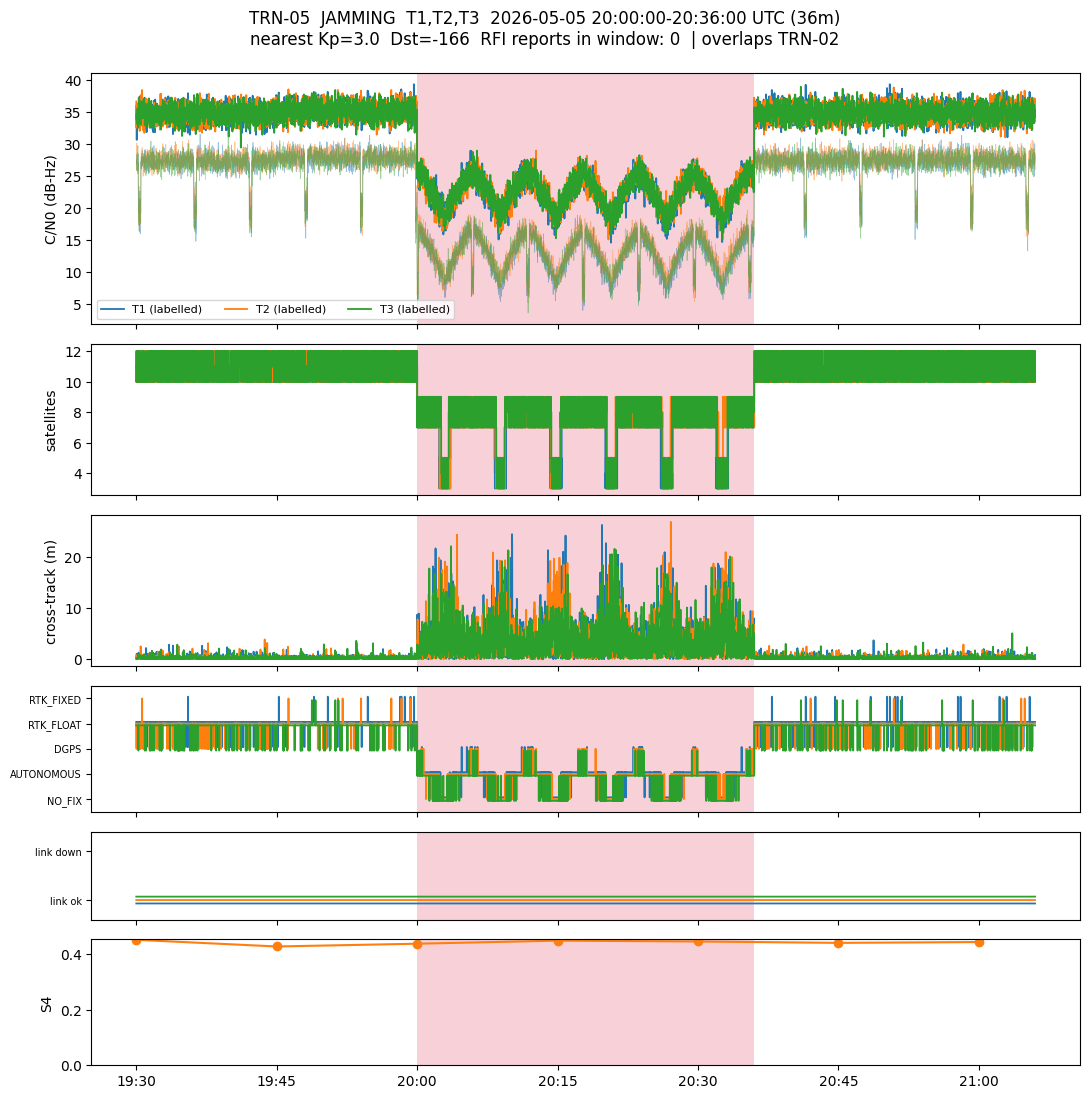

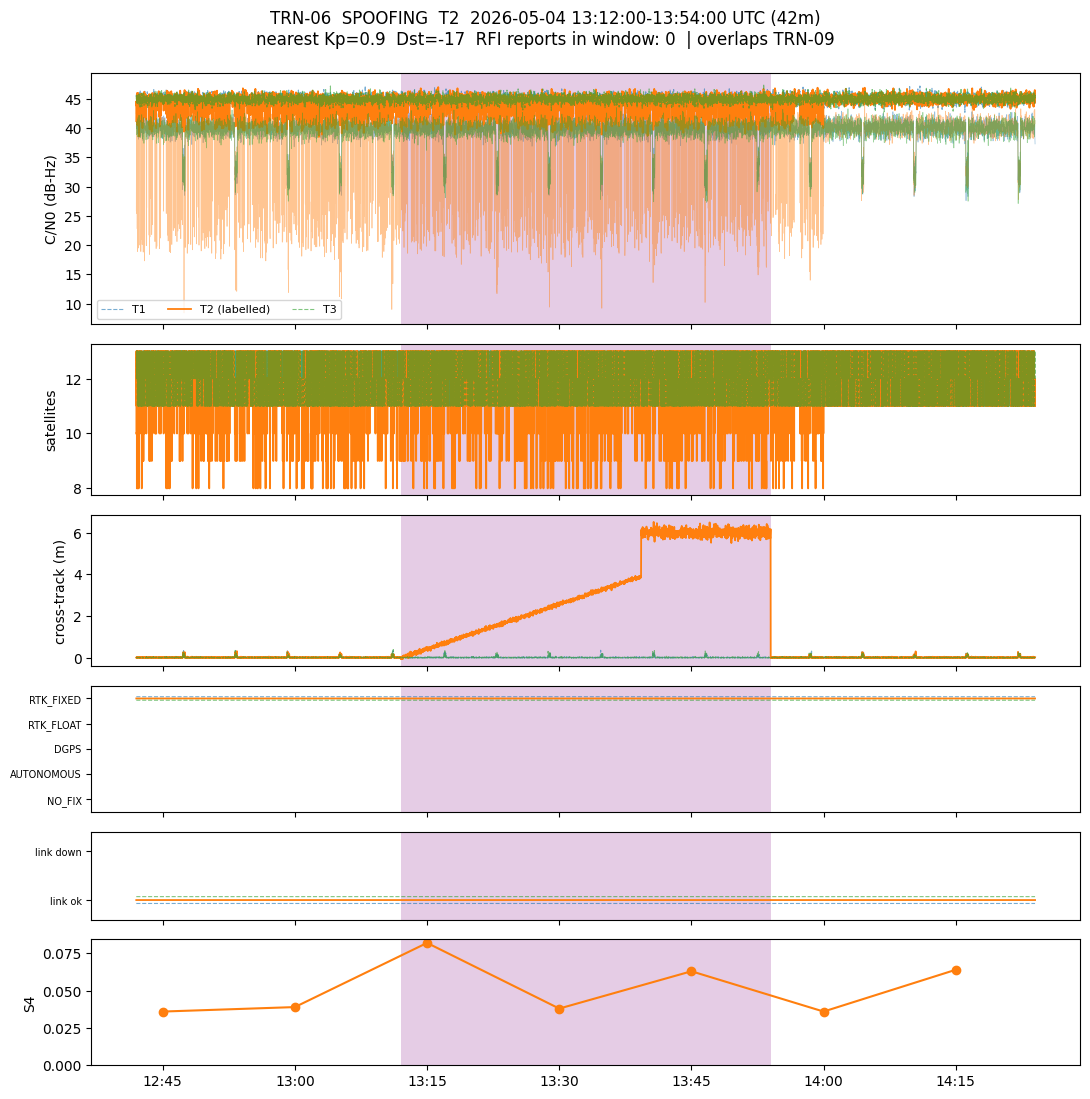

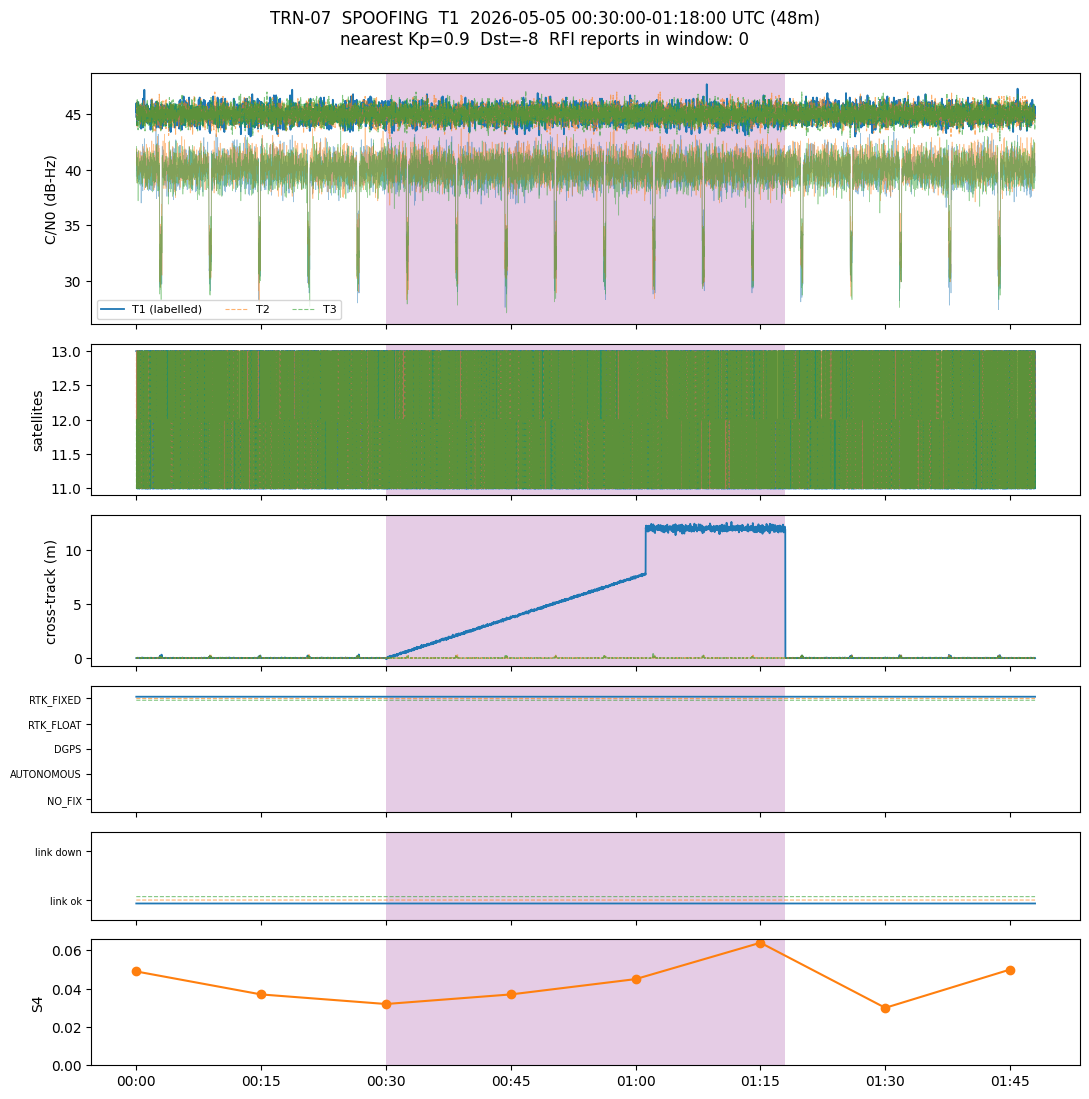

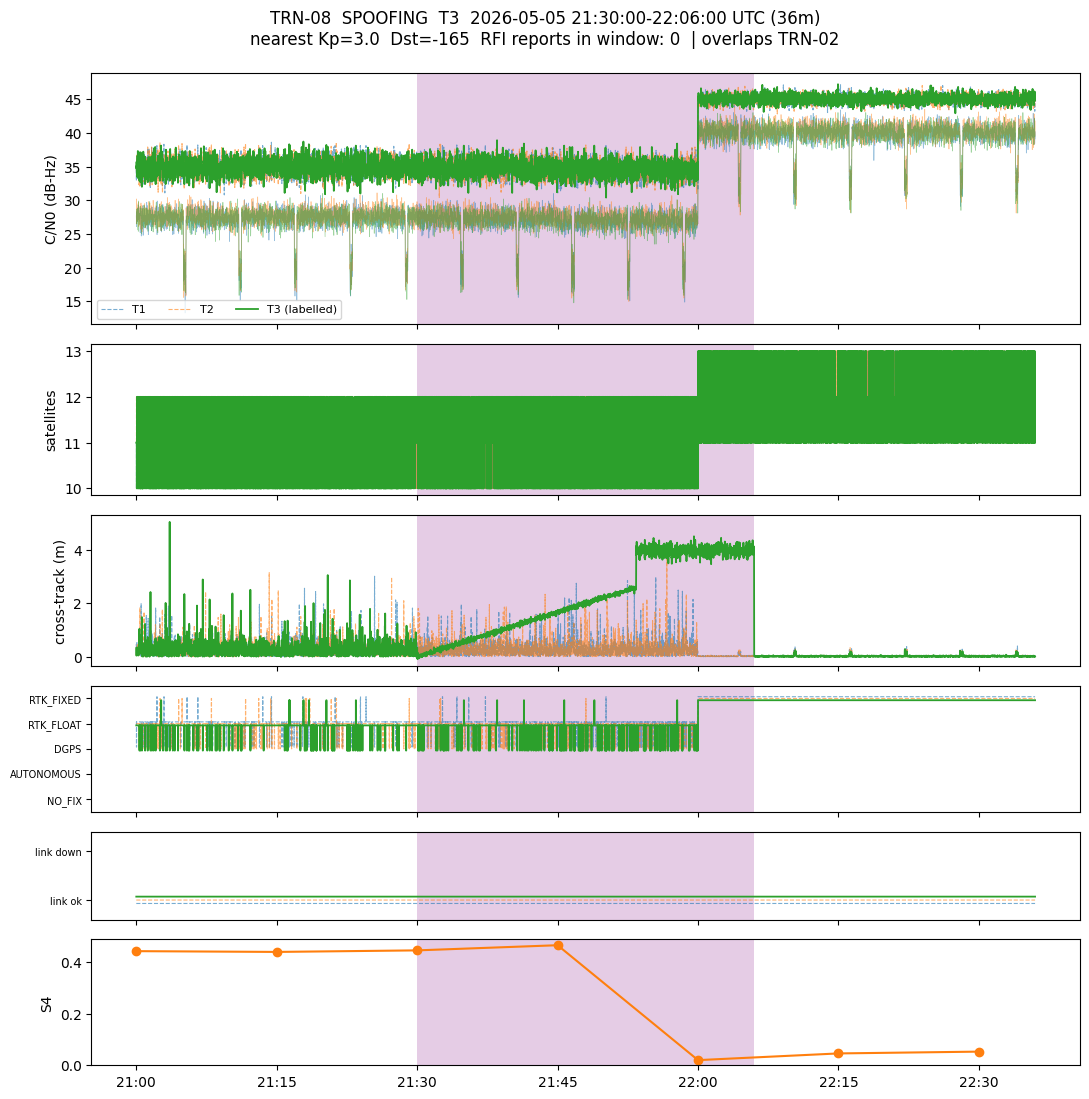

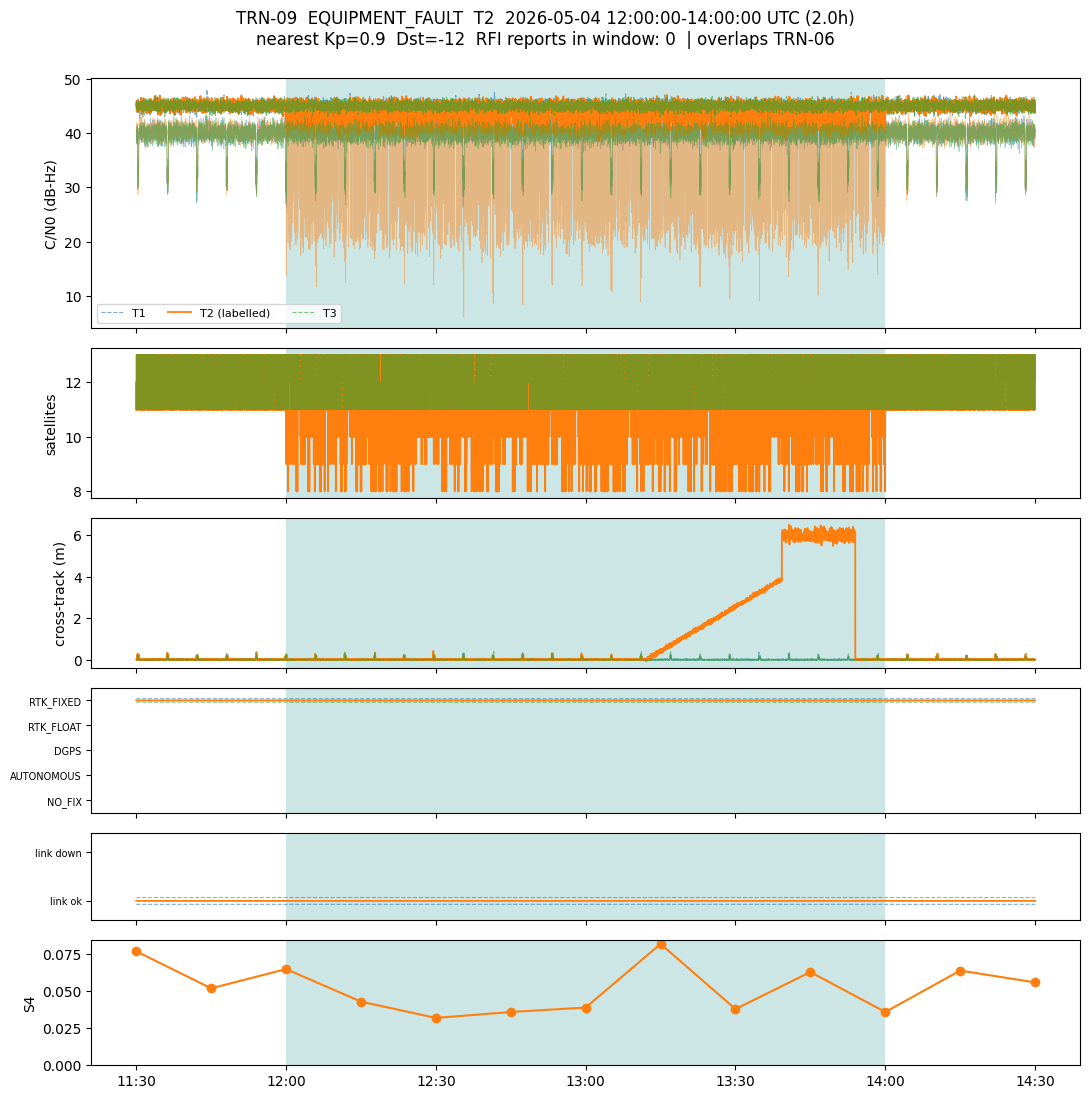

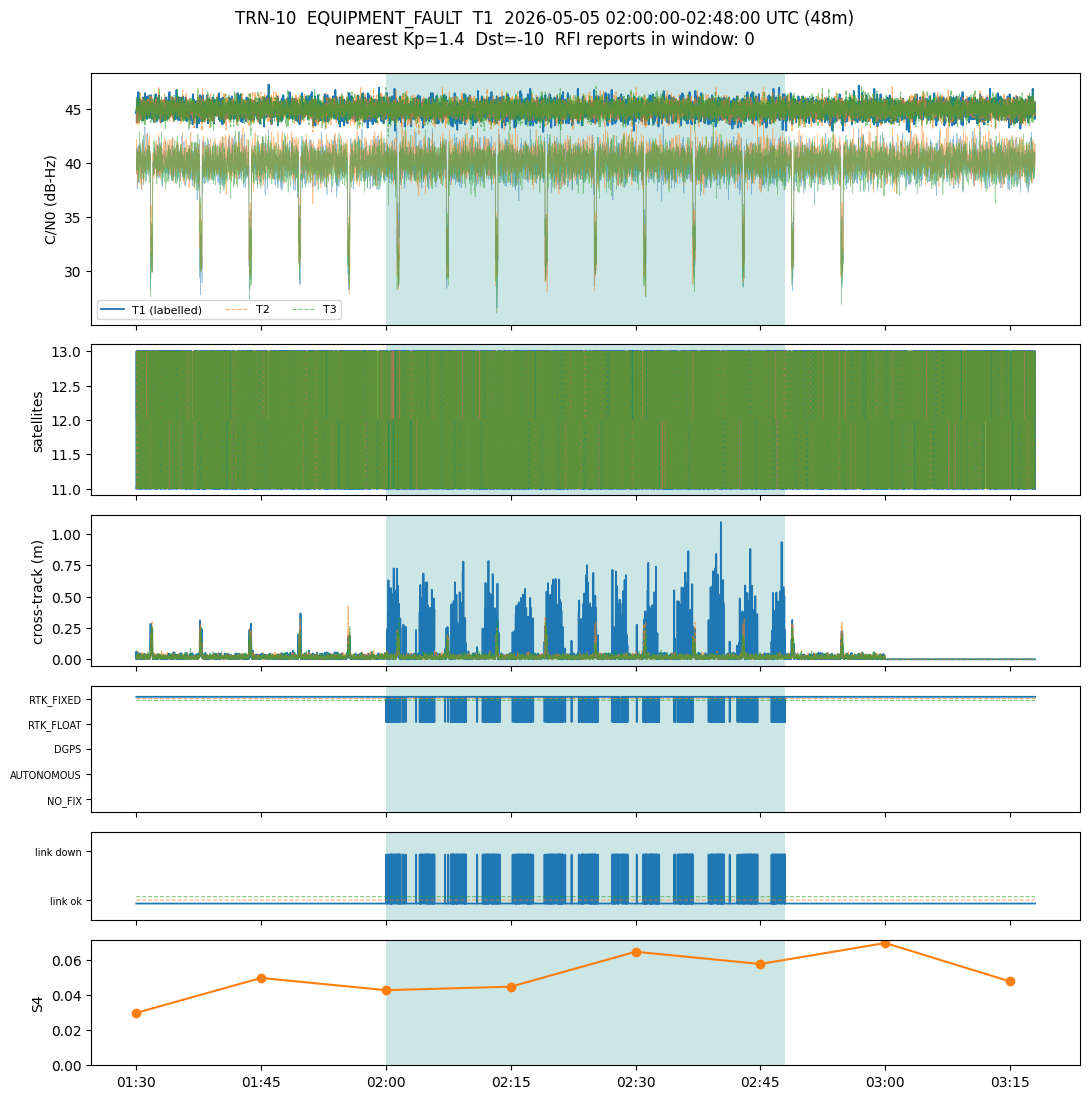

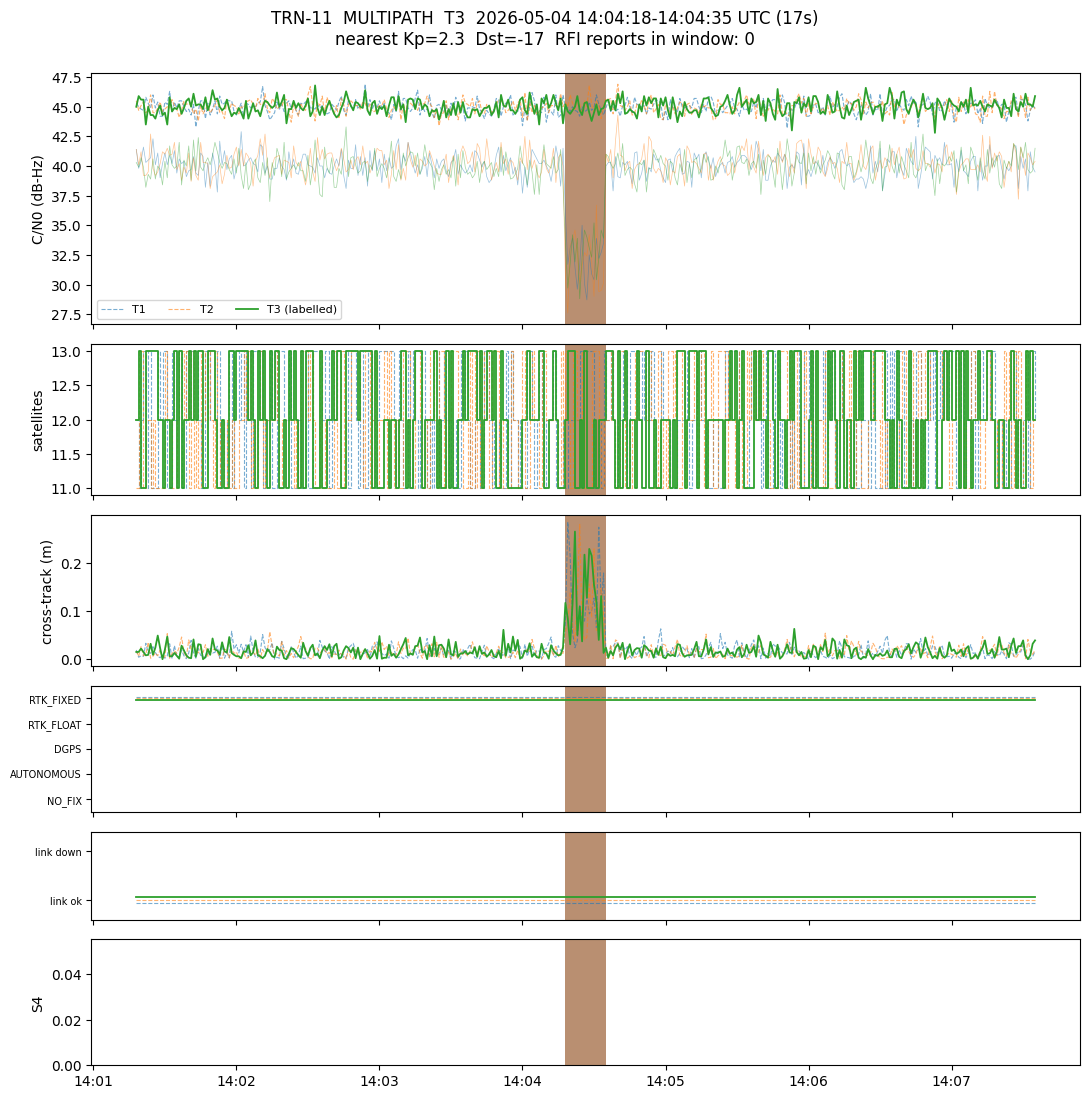

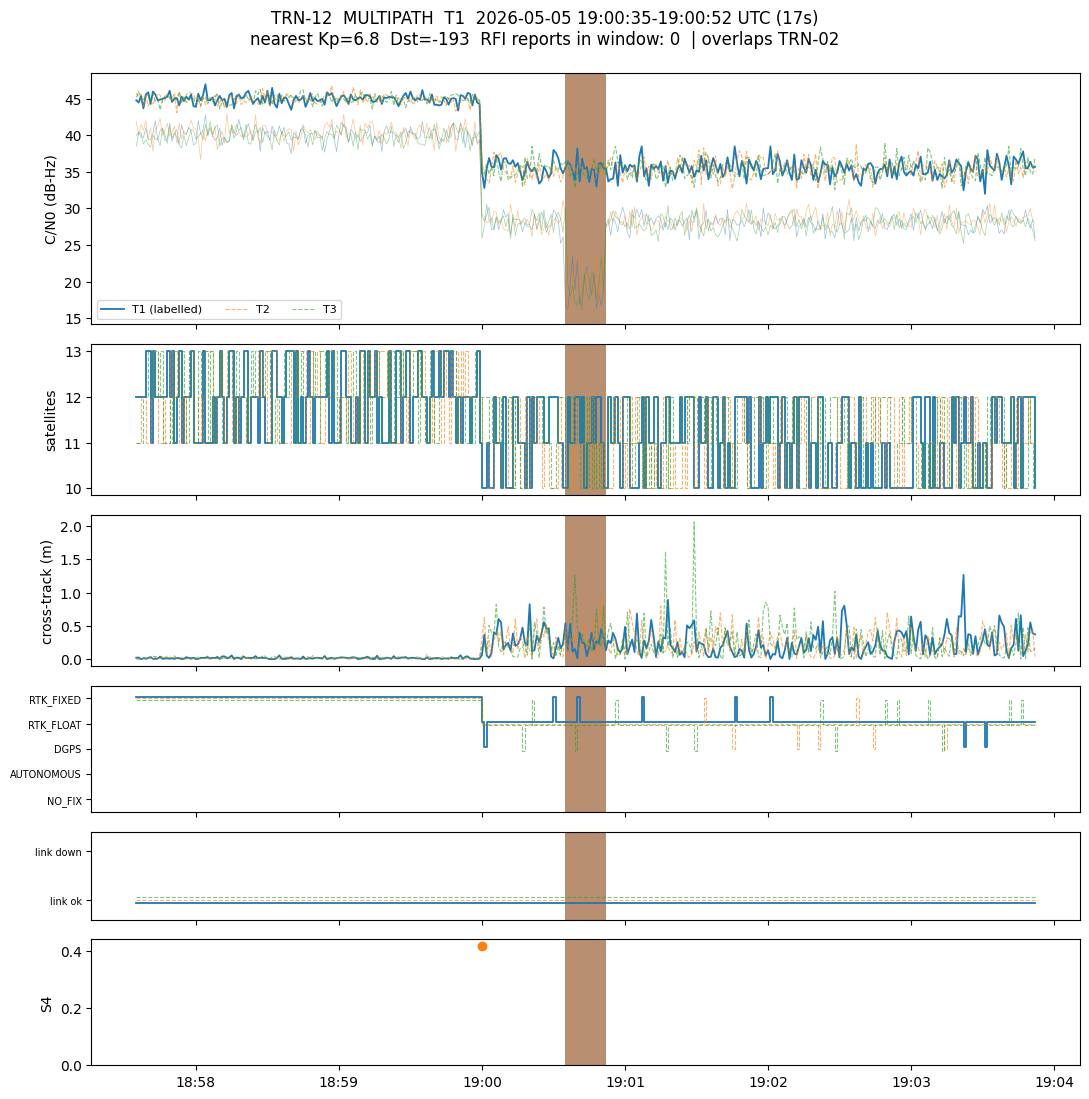

In [4]:
def plot_episode(i):
    e = eps[i]
    m = margin(e)
    lo, hi = e["s"] - m, e["e"] + m
    fig, ax = plt.subplots(6, 1, figsize=(11, 11), sharex=True, gridspec_kw={"height_ratios": [2, 1.2, 1.2, 1.0, 0.7, 1.0]})
    off = {"T1": -0.07, "T2": 0.0, "T3": 0.07}      # small vertical offsets so identical step lines stay visible
    for t in TR:
        x = by[t].loc[lo:hi]
        lab = t in e["trs"]
        kw = dict(color=TCOL[t], lw=1.3 if lab else 0.8, alpha=1.0 if lab else 0.6, ls="-" if lab else "--")
        ax[0].plot(x.index, x.mean_cn0_dbhz, label=t + (" (labelled)" if lab else ""), **kw)
        ax[0].plot(x.index, x.min_cn0_dbhz, color=TCOL[t], lw=0.5, alpha=0.45)
        ax[1].plot(x.index, x.num_sats, drawstyle="steps-post", **kw)
        ax[2].plot(x.index, x.cross_track_error_m, **kw)
        ax[3].plot(x.index, x.fix_rank + off[t], drawstyle="steps-post", **kw)
        ax[4].plot(x.index, x.link_down + off[t], drawstyle="steps-post", **kw)
    ax[0].set_ylabel("C/N0 (dB-Hz)"); ax[0].legend(loc="lower left", ncol=3, fontsize=8)
    ax[1].set_ylabel("satellites"); ax[2].set_ylabel("cross-track (m)")
    ax[3].set_yticks(range(len(FIX_ORDER)), FIX_ORDER, fontsize=7); ax[3].set_ylim(len(FIX_ORDER) - 0.5, -0.5)
    ax[4].set_yticks([0, 1], ["link ok", "link down"], fontsize=7); ax[4].set_ylim(-0.4, 1.4)
    f = s4[(s4.ts >= lo) & (s4.ts <= hi)]
    ax[5].plot(f.ts, f.s4, "o-", color="C1"); ax[5].set_ylabel("S4"); ax[5].set_ylim(bottom=0)
    reports = rfi[(rfi.ts >= lo) & (rfi.ts <= hi)]
    for a in ax:
        a.axvspan(e["s"], e["e"], color=COLOR[e["class"]], alpha=0.2 if e["dur_s"] > 120 else 0.6, lw=0)
        for r in reports.itertuples():
            a.axvline(r.ts, color="red", ls=":", lw=1)
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=timezone.utc))
    k, d = near(kp, "kp", e["s"]), near(dst, "dst", e["s"])
    ov = overlapping(e, back=pd.Timedelta(0))
    fig.suptitle(f"{e['id']}  {e['class']}  {','.join(e['trs'])}  {e['s']:%Y-%m-%d %H:%M:%S}-{e['e']:%H:%M:%S} UTC ({fmt_dur(e['dur_s'])})\n"
                 f"nearest Kp={k:.1f}  Dst={d:.0f}  RFI reports in window: {len(reports)}"
                 + (f"  | overlaps {','.join(ov)}" if ov else ""), y=0.995)
    fig.tight_layout(); plt.show()
    if len(reports):
        print(reports.drop(columns=["text"]).to_string(index=False))

for i in range(len(eps)):
    plot_episode(i)

## All episodes overlaid, by class

Every episode is aligned so **t = 0 is the episode start**. Each thin line is one episode (mean over its labelled
tractors, 10 s smoothing), thick lines are the class mean, `x` marks where an episode ends (when it ends before the right
edge). The view is clipped to -30..+130 min, so the 3 h and 5 h space-weather episodes run off the right.

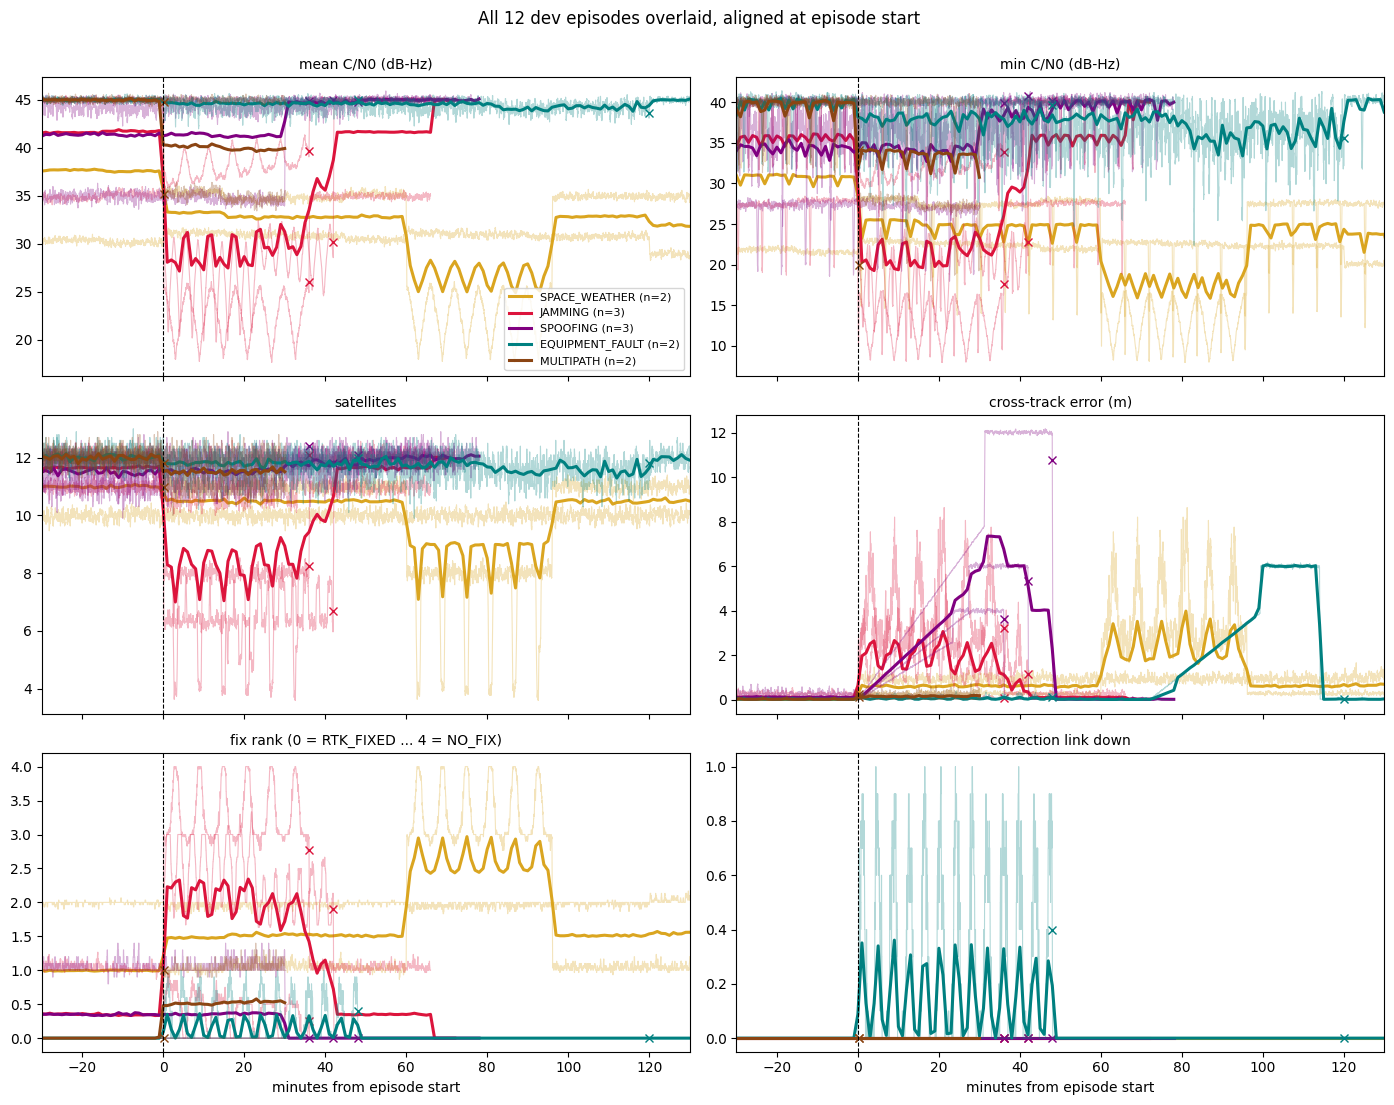

In [5]:
SIGNALS = [("mean_cn0_dbhz", "mean C/N0 (dB-Hz)"), ("min_cn0_dbhz", "min C/N0 (dB-Hz)"), ("num_sats", "satellites"),
           ("cross_track_error_m", "cross-track error (m)"), ("fix_rank", "fix rank (0 = RTK_FIXED ... 4 = NO_FIX)"), ("link_down", "correction link down")]
XLIM = (-30, 130)


def aligned(e, col, smooth="10s"):
    a, b = e["s"] - pd.Timedelta(minutes=30), min(e["e"] + pd.Timedelta(minutes=30), e["s"] + pd.Timedelta(minutes=XLIM[1] + 5))
    y = pd.concat([by[t].loc[a:b, col] for t in e["trs"]], axis=1).mean(axis=1).rolling(smooth).mean()
    y.index = (y.index - e["s"]).total_seconds() / 60
    return y


fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
for ax, (col, title) in zip(axes.flat, SIGNALS):
    for cls in CLASSES:
        idx = [e for e in eps if e["class"] == cls]
        curves = [aligned(e, col) for e in idx]
        for e, y in zip(idx, curves):
            ax.plot(y.index, y.values, color=COLOR[cls], alpha=0.3, lw=0.8)
            if e["min"] <= XLIM[1]:
                ax.plot(e["min"], y.iloc[(y.index - e["min"]).__abs__().argmin()], "x", color=COLOR[cls], ms=6)
        grid = pd.concat([c.groupby(np.round(c.index)).mean() for c in curves], axis=1).mean(axis=1)
        ax.plot(grid.index, grid.values, color=COLOR[cls], lw=2.2, label=f"{cls} (n={len(idx)})")
    ax.axvline(0, color="k", lw=0.8, ls="--"); ax.set_title(title, fontsize=10); ax.set_xlim(*XLIM)
for ax in axes[-1]:
    ax.set_xlabel("minutes from episode start")
axes.flat[0].legend(fontsize=8)
fig.suptitle(f"All {len(eps)} dev episodes overlaid, aligned at episode start", y=1.0)
fig.tight_layout(); plt.show()

### Within-episode snapshot by class

One row per episode: mean of each signal *inside* the episode (averaged over its labelled tractors), plus the SDA values in
effect at the onset and the number of RFI reports that arrived within 40 min of the onset. Sorted by class.

In [6]:
rows = []
for e in eps:
    inside = pd.concat([seg(t, e["s"], e["e"]) for t in e["trs"]])
    r = {"class": e["class"], "id": e["id"], "tractors": ",".join(e["trs"]), "dur": fmt_dur(e["dur_s"]), "dur_min": e["min"]}
    r.update({c: inside[c].mean() for c, _ in SIGNALS})
    r.update({"s4_near": near(s4, "s4", e["s"]), "kp_near": near(kp, "kp", e["s"]), "dst_near": near(dst, "dst", e["s"]),
              "rfi_reports_40min": int(((rfi.ts >= e["s"]) & (rfi.ts <= e["s"] + pd.Timedelta("40min"))).sum())})
    rows.append(r)
snap = pd.DataFrame(rows).sort_values(["class", "id"]).set_index(["class", "id"])
display(snap.round(2))
display(snap.groupby("class").mean(numeric_only=True).round(2))

tractors   dur  dur_min  mean_cn0_dbhz  min_cn0_dbhz  num_sats  cross_track_error_m  fix_rank  link_down  s4_near  kp_near  dst_near  rfi_reports_40min
class           id                                                                                                                                                             
EQUIPMENT_FAULT TRN-09        T2  2.0h   120.00          44.21         36.20     11.56                 1.19      0.00        0.0     0.06      0.9     -12.0                  0
                TRN-10        T1   48m    48.00          44.99         39.68     12.01                 0.09      0.30        0.3     0.04      1.4     -10.0                  0
JAMMING         TRN-03  T1,T2,T3   42m    42.00          27.59         19.74      6.57                 1.90      2.33        0.0     0.05      2.3     -13.0                  1
                TRN-04     T1,T3   36m    36.00          38.19         31.79     11.13                 0.11      0.41        0.0     0.07      2.0     -15.0                  1
                TRN-05  T1,T2,T3   36m    36.00          22.46         12.79      7.31                 3.88      3.28        0.0     0.44      3.0    -166.0                  0
MULTIPATH       TRN-11        T3   17s     0.28          44.79         32.73     11.82                 0.12      0.00        0.0     0.04      2.3     -17.0                  0
                TRN-12        T1   17s     0.28          35.42         19.09     11.24                 0.26      0.94        0.0     0.42      6.8    -193.0                  0
SPACE_WEATHER   TRN-01  T1,T2,T3  5.0h   300.00          29.66         20.59     10.00                 1.01      2.02        0.0     0.65      9.0    -300.0                  0
                TRN-02  T1,T2,T3  3.0h   180.00          32.42         24.28     10.26                 1.09      1.50        0.0     0.42      6.8    -193.0                  0
SPOOFING        TRN-06        T2   42m    42.00          44.20         36.13     11.57                 3.37      0.00        0.0     0.08      0.9     -17.0                  0
                TRN-07        T1   48m    48.00          44.99         39.69     11.96                 6.74      0.00        0.0     0.03      0.9      -8.0                  0
                TRN-08        T3   36m    36.00          36.39         28.85     11.17                 2.24      0.89        0.0     0.45      3.0    -165.0                  0

,dur_min,mean_cn0_dbhz,min_cn0_dbhz,num_sats,cross_track_error_m,fix_rank,link_down,s4_near,kp_near,dst_near,rfi_reports_40min
class,,,,,,,,,,,
EQUIPMENT_FAULT,84.00,44.60,37.94,11.79,0.64,0.15,0.15,0.05,1.15,-11.00,0.00
JAMMING,38.00,29.41,21.44,8.33,1.97,2.01,0.00,0.19,2.43,-64.67,0.67
MULTIPATH,0.28,40.11,25.91,11.53,0.19,0.47,0.00,0.23,4.55,-105.00,0.00
SPACE_WEATHER,240.00,31.04,22.44,10.13,1.05,1.76,0.00,0.53,7.90,-246.50,0.00
SPOOFING,42.00,41.86,34.89,11.57,4.12,0.30,0.00,0.19,1.60,-63.33,0.00


## Interactive comparison

Pick which episodes, classes and signals to compare. Same stacked-panel layout as the per-episode plots. Requires
`ipywidgets` (`pip install ipywidgets`); without it this cell just prints a note.

* **Classes / Episodes**: toggle whole classes, or pick individual episodes (ctrl/cmd-click for several).
* **Panels**: show or hide each signal panel, plus a **Durations** bar chart (log scale: 17 s to 5 h).
* **Tractors**: average over each episode's labelled tractors, over all three, or show a single tractor.
* **Window sliders**: minutes shown before the episode start and after its end. **Smoothing**: rolling mean in seconds
  (not applied to fix state / link). **Align**: `start` / `end` in minutes, or `normalised` (0 = start, 1 = end).
* **View**: individual episodes, class means, or both.

In [7]:
try:
    import ipywidgets as W
except ImportError:
    W = None
    print("ipywidgets is not installed in this kernel; `pip install ipywidgets` and re-run this cell for the interactive view.")

PANELS = {  # label -> (columns, y label, height ratio)
    "C/N0": (["mean_cn0_dbhz", "min_cn0_dbhz"], "C/N0 (dB-Hz)", 2.0),
    "Satellites": (["num_sats"], "satellites", 1.3),
    "Cross-track": (["cross_track_error_m"], "cross-track (m)", 1.3),
    "Fix state": (["fix_rank"], "fix rank", 0.9),
    "Base link": (["link_down"], "link down", 0.8),
    "S4": (["s4"], "S4", 1.3),
}
LINESTYLE = {"mean_cn0_dbhz": "-", "min_cn0_dbhz": ":"}
DISCRETE = {"fix_rank", "link_down"}
EP_LABEL = [f"{e['id']}  {e['class']}  {','.join(e['trs'])}  {e['s']:%m-%d %H:%M}" for e in eps]
WHO = ["labelled tractors", "all tractors", *TR]


def ep_series(e, col, smooth_s, before, after, align, who):
    """One episode's signal indexed by x (min from start/end, or fraction of the episode length)."""
    trs = e["trs"] if who == "labelled tractors" else (TR if who == "all tractors" else [who])
    a, b = e["s"] - pd.Timedelta(minutes=before), e["e"] + pd.Timedelta(minutes=after)
    x = pd.concat([by[t].loc[a:b, col] for t in trs], axis=1).mean(axis=1)
    if smooth_s > 1 and col not in DISCRETE:
        x = x.rolling(f"{int(smooth_s)}s").mean()
    sec = (x.index - (e["e"] if align == "end" else e["s"])).total_seconds()
    x.index = sec / e["dur_s"] if align == "normalised" else sec / 60
    return x


def render(classes, episodes, panels, before, after, smooth_s, align, view, shade, who):
    sel = [e for e in eps if e["class"] in classes and EP_LABEL[e["i"]] in episodes]
    show_dur = "Durations" in panels
    panels = [p for p in PANELS if p in panels]
    if not sel or not (panels or show_dur):
        print("Nothing selected."); return
    ratios = [PANELS[p][2] for p in panels] + ([2.2] if show_dur else [])
    fig = plt.figure(figsize=(11, 1.0 + 1.9 * len(ratios)))
    gs = fig.add_gridspec(len(ratios), 1, height_ratios=ratios)
    axes = []
    for k in range(len(panels)):
        axes.append(fig.add_subplot(gs[k], sharex=axes[0] if axes else None))
        if k < len(panels) - 1:
            plt.setp(axes[-1].get_xticklabels(), visible=False)
    unit = {"start": "min from episode start", "end": "min from episode end", "normalised": "episode length (0 = start, 1 = end)"}[align]
    step = 0.02 if align == "normalised" else 0.5
    for ax, p in zip(axes, panels):
        cols, ylab, _ = PANELS[p]
        for col in cols:
            for cls in [c for c in CLASSES if any(e["class"] == c for e in sel)]:
                idx = [e for e in sel if e["class"] == cls]
                curves = []
                for e in idx:
                    if col == "s4":   # 15-min feed: plotted as points
                        f = s4[(s4.ts >= e["s"] - pd.Timedelta(minutes=before)) & (s4.ts <= e["e"] + pd.Timedelta(minutes=after))]
                        ref = e["e"] if align == "end" else e["s"]
                        xs = (f.ts - ref).dt.total_seconds() / (e["dur_s"] if align == "normalised" else 60)
                        ax.plot(xs, f.s4, "o-", color=COLOR[cls], alpha=0.6, ms=4, lw=1)
                        continue
                    y = ep_series(e, col, smooth_s, before, after, align, who)
                    curves.append(y)
                    if view in ("Individual", "Both"):
                        ax.plot(y.index, y.values, LINESTYLE.get(col, "-"), color=COLOR[cls], alpha=0.9 if len(sel) == 1 else 0.35,
                                lw=1.2 if len(sel) > 1 else 1.5, drawstyle="steps-post" if col in ("num_sats", *DISCRETE) else "default")
                if curves and view in ("Class means", "Both"):
                    m = pd.concat([c.groupby((c.index / step).round() * step).mean() for c in curves], axis=1).mean(axis=1)
                    ax.plot(m.index, m.values, LINESTYLE.get(col, "-"), color=COLOR[cls], lw=2.4, label=cls if col == cols[0] else None)
        ax.set_ylabel(ylab)
        if p == "Fix state":
            ax.set_yticks(range(len(FIX_ORDER)), FIX_ORDER, fontsize=7); ax.set_ylim(len(FIX_ORDER) - 0.5, -0.5)
        if p == "C/N0":
            ax.plot([], [], "k-", label="mean"); ax.plot([], [], "k:", label="min")
        if shade:
            for e in sel:
                lo, hi = {"start": (0, e["min"]), "end": (-e["min"], 0), "normalised": (0, 1)}[align]
                ax.axvspan(lo, hi, color=COLOR[e["class"]], alpha=0.12 if len(sel) > 1 else 0.2)
        ax.axvline(0, color="k", lw=0.6, ls="--")
        if align == "normalised":
            ax.set_xlim(-0.5, 1.5)
    if axes:
        h, l = axes[0].get_legend_handles_labels()
        if h:
            axes[0].legend(h, l, loc="upper right", ncol=min(len(l), 4), fontsize=8)
        axes[-1].set_xlabel(unit)
    if show_dur:   # not on the time axis: one bar per selected episode, grouped by class
        ad = fig.add_subplot(gs[len(panels)])
        order = sorted(sel, key=lambda e: (CLASS_LIST.index(e["class"]), e["i"]))
        ad.bar(range(len(order)), [e["min"] for e in order], color=[COLOR[e["class"]] for e in order], alpha=0.85)
        for k, e in enumerate(order):
            ad.text(k, e["min"] * 1.15, fmt_dur(e["dur_s"]), ha="center", fontsize=8)
        ad.set_yscale("log"); ad.set_ylim(0.1, 3 * max(e["min"] for e in order))
        ad.set_xticks(range(len(order)), [f"{e['id'][-2:]} {','.join(e['trs'])}\n{e['class'][:5]}" for e in order], fontsize=7)
        ad.set_ylabel("duration (min, log)")
    if len(sel) == 1:
        e = sel[0]
        r = rfi[(rfi.ts >= e["s"]) & (rfi.ts <= e["e"] + pd.Timedelta("40min"))]
        title = (f"{e['id']}  {e['class']}  {','.join(e['trs'])}  {e['s']:%Y-%m-%d %H:%M:%S}-{e['e']:%H:%M:%S} UTC\n"
                 f"nearest Kp={near(kp, 'kp', e['s']):.1f}  Dst={near(dst, 'dst', e['s']):.0f}  RFI reports within 40 min: {len(r)}")
    else:
        title = f"{len(sel)} episodes  |  view: {view}, smoothing {int(smooth_s)} s, tractors: {who}"
    fig.suptitle(title, y=0.995); fig.tight_layout(); fig.subplots_adjust(hspace=0.4); plt.show(); plt.close(fig)


if W is not None:
    class_tg = {c: W.ToggleButton(value=True, description=c, layout=W.Layout(width="150px")) for c in CLASSES}
    ep_sel = W.SelectMultiple(options=EP_LABEL, value=tuple(EP_LABEL), rows=12, layout=W.Layout(width="300px"))
    panel_cb = {p: W.Checkbox(value=True, description=p, indent=False) for p in [*PANELS, "Durations"]}
    before = W.IntSlider(value=30, min=0, max=120, step=5, description="before (min)", continuous_update=False)
    after = W.IntSlider(value=30, min=0, max=120, step=5, description="after (min)", continuous_update=False)
    smooth = W.IntSlider(value=10, min=1, max=300, step=1, description="smooth (s)", continuous_update=False)
    align = W.ToggleButtons(options=["start", "end", "normalised"], value="start", description="align")
    view = W.ToggleButtons(options=["Individual", "Class means", "Both"], value="Both", description="view")
    who = W.Dropdown(options=WHO, value="labelled tractors", description="tractors")
    shade = W.Checkbox(value=True, description="shade episode spans", indent=False)
    btn_all, btn_none = W.Button(description="all episodes"), W.Button(description="none")
    btn_all.on_click(lambda _: setattr(ep_sel, "value", tuple(EP_LABEL)))
    btn_none.on_click(lambda _: setattr(ep_sel, "value", ()))
    out = W.interactive_output(
        lambda **kw: render([c for c in CLASSES if kw["c_" + c]], list(kw["episodes"]), [p for p in [*PANELS, "Durations"] if kw["p_" + p]],
                            kw["before"], kw["after"], kw["smooth"], kw["align"], kw["view"], kw["shade"], kw["who"]),
        {**{"c_" + c: b for c, b in class_tg.items()}, **{"p_" + p: b for p, b in panel_cb.items()},
         "episodes": ep_sel, "before": before, "after": after, "smooth": smooth, "align": align, "view": view, "shade": shade, "who": who})
    controls = W.VBox([
        W.HTML("<b>Classes</b>"), W.HBox(list(class_tg.values()), layout=W.Layout(flex_flow="row wrap")),
        W.HBox([
            W.VBox([W.HTML("<b>Episodes</b>"), ep_sel, W.HBox([btn_all, btn_none])]),
            W.VBox([W.HTML("<b>Panels</b>"), *panel_cb.values(), shade], layout=W.Layout(margin="0 20px")),
            W.VBox([W.HTML("<b>Window / smoothing</b>"), before, after, smooth, align, view, who]),
        ]),
    ])
    display(controls, out)

ipywidgets is not installed in this kernel; `pip install ipywidgets` and re-run this cell for the interactive view.


# Extended checks

Fleet, RFI, positions, context, column scan, edge timing, whole-dataset detection and a rule classifier, all on the same
loaded data. Remember there are only 12 labelled episodes, several of which overlap, so small-sample caution applies
throughout.

## 1. Coverage check

Every tractor needs 1 Hz telemetry through every episode window (30 min before onset to the end), and the labelled
tractors should be *working* during the episode (the scoring only concerns working machines).

In [8]:
rows = []
for e in eps:
    a, b = e["s"] - PAD, e["e"]
    r = {"id": e["id"], "class": e["class"], "labelled": ",".join(e["trs"]), "expected_rows": int((b - a).total_seconds())}
    r.update({t: len(by[t].loc[a: b - SEC]) for t in TR})
    r["moving_frac_inside(min)"] = min(seg(t, e["s"], e["e"]).moving.mean() for t in e["trs"])
    r["moving_frac_baseline"] = np.mean([seg(t, a, e["s"]).moving.mean() for t in e["trs"]])
    rows.append(r)
cov = pd.DataFrame(rows)
display(cov.round(2))
print(f"rows: {len(tel):,} | NaNs: {int(tel[['speed_mps', 'cross_track_error_m', 'num_sats', 'mean_cn0_dbhz', 'min_cn0_dbhz', 'lat', 'lon']].isna().sum().sum())}"
      f" | unknown fix states: {int(tel.fix_rank.isna().sum())}")
print("Complete 1 Hz coverage on every tractor for every episode window:", all((cov[t] == cov["expected_rows"]).all() for t in TR))
print("Labelled tractors moving for the whole episode in every episode:", bool((cov["moving_frac_inside(min)"] == 1).all()))
print("Episodes whose baseline window is partly parked:", cov.loc[cov["moving_frac_baseline"] < 1, "id"].tolist())

,id,class,labelled,expected_rows,T1,T2,T3,moving_frac_inside(min),moving_frac_baseline
0,TRN-01,SPACE_WEATHER,"T1,T2,T3",19800,19800,19800,19800,1.0,0.0
1,TRN-02,SPACE_WEATHER,"T1,T2,T3",12600,12600,12600,12600,1.0,1.0
2,TRN-03,JAMMING,"T1,T2,T3",4320,4320,4320,4320,1.0,1.0
3,TRN-04,JAMMING,"T1,T3",3960,3960,3960,3960,1.0,1.0
4,TRN-05,JAMMING,"T1,T2,T3",3960,3960,3960,3960,1.0,1.0
5,TRN-06,SPOOFING,T2,4320,4320,4320,4320,1.0,1.0
6,TRN-07,SPOOFING,T1,4680,4680,4680,4680,1.0,1.0
7,TRN-08,SPOOFING,T3,3960,3960,3960,3960,1.0,1.0
8,TRN-09,EQUIPMENT_FAULT,T2,9000,9000,9000,9000,1.0,1.0
9,TRN-10,EQUIPMENT_FAULT,T1,4680,4680,4680,4680,1.0,1.0


rows: 777,600 | NaNs: 0 | unknown fix states: 0
Complete 1 Hz coverage on every tractor for every episode window: True
Labelled tractors moving for the whole episode in every episode: True
Episodes whose baseline window is partly parked: ['TRN-01']


## 2. Fleet check

C/N0 drop on **all** tractors for each episode, two ways: against the 30 min before onset (`drop30`), and against a
clear-sky reference (`dropclr`: each tractor's median mean C/N0 while moving, outside every labelled dev episode). The
second is robust when the baseline is already degraded by an overlapping episode. A tractor counts as **hit** when it drops
more than `THRESH_DB`. The `hit` set is compared with the labelled tractor set.

In [9]:
THRESH_DB = 5
in_ep = pd.Series(False, index=tel.index)
for e in eps:
    in_ep |= (tel.ts >= e["s"]) & (tel.ts < e["e"])
clear = tel[~in_ep & tel.moving & (tel.ts < EVAL_START)].groupby("tractor_id")["mean_cn0_dbhz"].median()
print("clear-sky mean C/N0 reference (dB-Hz):", clear.round(2).to_dict())


def level(t, a, b):
    return by[t].loc[a: b - SEC, "mean_cn0_dbhz"].mean()


rows = []
for e in eps:
    r = {"id": e["id"], "class": e["class"], "labelled": ",".join(e["trs"])}
    for t in TR:
        r[f"drop30_{t}"] = level(t, e["s"] - PAD, e["s"]) - level(t, e["s"], e["e"])
    for t in TR:
        r[f"dropclr_{t}"] = clear[t] - level(t, e["s"], e["e"])
    hit30 = [t for t in TR if r[f"drop30_{t}"] > THRESH_DB]
    hit = [t for t in TR if r[f"dropclr_{t}"] > THRESH_DB]
    r["n_hit_30"], r["n_hit"], r["hit"] = len(hit30), len(hit), ",".join(hit)
    r["hit_vs_labelled_iou"] = len(set(hit) & set(e["trs"])) / len(set(hit) | set(e["trs"]))
    r["baseline_also_overlaps"] = ",".join(overlapping(e))
    rows.append(r)
fleet = pd.DataFrame(rows)
display(fleet.round(2))
print("Tractors hit (clear-sky reference) by class:")
display(pd.crosstab(fleet["class"], fleet["n_hit"]))
print("Episodes where the hit set equals the labelled set:", fleet.loc[fleet["hit_vs_labelled_iou"] == 1, "id"].tolist())

clear-sky mean C/N0 reference (dB-Hz): {'T1': 45.0, 'T2': 45.0, 'T3': 45.0}


,id,class,labelled,drop30_T1,drop30_T2,drop30_T3,dropclr_T1,dropclr_T2,dropclr_T3,n_hit_30,n_hit,hit,hit_vs_labelled_iou,baseline_also_overlaps
0,TRN-01,SPACE_WEATHER,"T1,T2,T3",0.56,0.62,0.62,15.34,15.34,15.34,0,3,"T1,T2,T3",1.00,
1,TRN-02,SPACE_WEATHER,"T1,T2,T3",12.62,12.54,12.58,12.61,12.54,12.58,3,3,"T1,T2,T3",1.00,"TRN-05,TRN-08,TRN-12"
2,TRN-03,JAMMING,"T1,T2,T3",17.88,14.34,20.02,17.88,14.34,20.00,3,3,"T1,T2,T3",1.00,
3,TRN-04,JAMMING,"T1,T3",5.58,2.95,8.03,5.57,2.93,8.05,2,2,"T1,T3",1.00,
4,TRN-05,JAMMING,"T1,T2,T3",12.77,12.41,12.42,22.77,22.39,22.46,3,3,"T1,T2,T3",1.00,TRN-02
5,TRN-06,SPOOFING,T2,0.01,0.01,-0.04,0.02,0.80,0.00,0,0,,0.00,TRN-09
6,TRN-07,SPOOFING,T1,0.01,-0.03,0.00,0.01,-0.02,-0.00,0,0,,0.00,
7,TRN-08,SPOOFING,T3,-1.48,-1.50,-1.45,8.57,8.58,8.61,0,3,"T1,T2,T3",0.33,TRN-02
8,TRN-09,EQUIPMENT_FAULT,T2,-0.00,0.79,0.00,0.01,0.79,0.00,0,0,,0.00,TRN-06
9,TRN-10,EQUIPMENT_FAULT,T1,0.00,0.01,-0.03,0.01,-0.01,-0.02,0,0,,0.00,


Tractors hit (clear-sky reference) by class:


n_hit,0,2,3
class,,,
EQUIPMENT_FAULT,2,0,0
JAMMING,0,1,2
MULTIPATH,1,0,1
SPACE_WEATHER,0,0,2
SPOOFING,2,0,1


Episodes where the hit set equals the labelled set: ['TRN-01', 'TRN-02', 'TRN-03', 'TRN-04', 'TRN-05']


## 3. RFI reports

The full report table. Reports have **one timestamp** (when it arrived; the event happened 10-30 min earlier), a band, a
confidence, a centre position and an uncertainty ellipse. Each report is matched to labelled episodes whose onset was
0-40 min before it. Reports matching nothing are false alarms, or belong to the unlabelled evaluation window.

In [10]:
RFI_DELAY_MAX = pd.Timedelta("40min")


def candidates(ts):
    return [e for e in eps if pd.Timedelta(0) <= ts - e["s"] <= RFI_DELAY_MAX]


rfi_t = rfi.copy()
cand = [candidates(t) for t in rfi_t["ts"]]
rfi_t["matched_episode"] = [",".join(e["id"] for e in c) for c in cand]
rfi_t["class"] = [",".join(e["class"] for e in c) if c else ("(eval window)" if t >= EVAL_START else "(no labelled episode)") for c, t in zip(cand, rfi_t["ts"])]
rfi_t["delay_min"] = [(t - c[0]["s"]).total_seconds() / 60 if c else np.nan for c, t in zip(cand, rfi_t["ts"])]
with pd.option_context("display.max_colwidth", None):
    display(rfi_t.sort_values("ts").reset_index(drop=True))

print("Per labelled episode: RFI reports arriving within 40 min of onset")
ep_rfi = pd.DataFrame([{"id": e["id"], "class": e["class"], "tractors": ",".join(e["trs"]), "reports": ",".join(r.id for r in rfi.itertuples() if pd.Timedelta(0) <= r.ts - e["s"] <= RFI_DELAY_MAX),
                        } for e in eps])
ep_rfi["n_reports"] = ep_rfi["reports"].map(lambda s: len(s.split(",")) if s else 0)
display(ep_rfi)
display(pd.crosstab(ep_rfi["class"], ep_rfi["n_reports"]))

,id,ts,band,confidence,centerLat,centerLon,semiMajor_km,semiMinor_km,text,matched_episode,class,delay_min
0,RFI-001,2026-05-04 16:44:48.993670+00:00,L1,0.60,46.908072,-97.192686,3.44,1.04,Possible intentional L1 interference detected by regional monitor; geolocation approximate.,TRN-03,JAMMING,14.816561
1,RFI-002,2026-05-04 21:10:43.395253+00:00,L1,0.55,46.906020,-97.212547,1.63,1.53,Possible intentional L1 interference detected by regional monitor; geolocation approximate.,TRN-04,JAMMING,10.723254
2,RFI-004,2026-05-05 10:36:00+00:00,L1,0.35,46.930000,-97.250000,6.00,3.50,Low-confidence interference candidate; may be storm-related receiver noise. Unconfirmed.,,(no labelled episode),NaN
3,RFI-003,2026-05-06 02:38:59.290612+00:00,L1,0.57,46.888896,-97.208767,3.50,1.91,Possible intentional L1 interference detected by regional monitor; geolocation approximate.,,(eval window),NaN


Per labelled episode: RFI reports arriving within 40 min of onset


,id,class,tractors,reports,n_reports
0,TRN-01,SPACE_WEATHER,"T1,T2,T3",,0
1,TRN-02,SPACE_WEATHER,"T1,T2,T3",,0
2,TRN-03,JAMMING,"T1,T2,T3",RFI-001,1
3,TRN-04,JAMMING,"T1,T3",RFI-002,1
4,TRN-05,JAMMING,"T1,T2,T3",,0
5,TRN-06,SPOOFING,T2,,0
6,TRN-07,SPOOFING,T1,,0
7,TRN-08,SPOOFING,T3,,0
8,TRN-09,EQUIPMENT_FAULT,T2,,0
9,TRN-10,EQUIPMENT_FAULT,T1,,0


n_reports,0,1
class,,
EQUIPMENT_FAULT,2,0
JAMMING,1,2
MULTIPATH,2,0
SPACE_WEATHER,2,0
SPOOFING,3,0


In [11]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


# Distance from each report's centre to each tractor's reported position when the report arrived. Reported position is
# not trusted during spoofing, and the ellipse orientation is not given, so semiMajor_km is used as a radius bound.
rows = []
for r in rfi_t.itertuples():
    row = {"id": r.id, "matched": r.matched_episode, "centre": f"{r.centerLat:.4f},{r.centerLon:.4f}", "semiMajor_km": r.semiMajor_km}
    for t in TR:
        q = by[t].iloc[by[t].index.get_indexer([r.ts], method="nearest")[0]]
        row[f"dist_{t}_km"] = haversine_km(r.centerLat, r.centerLon, q["lat"], q["lon"])
    row["tractors_within_semiMajor"] = ",".join(t for t in TR if row[f"dist_{t}_km"] <= r.semiMajor_km)
    c = candidates(r.ts)
    if c:
        lab = sorted({t for e in c for t in e["trs"]})
        oth = [t for t in TR if t not in lab]
        row["labelled"] = ",".join(lab)
        row["mean_dist_labelled_km"] = np.mean([row[f"dist_{t}_km"] for t in lab])
        row["mean_dist_other_km"] = np.mean([row[f"dist_{t}_km"] for t in oth]) if oth else np.nan
    rows.append(row)
rfi_dist = pd.DataFrame(rows)
display(rfi_dist.round(2))
f_km = haversine_km(tel.lat.min(), tel.lon.min(), tel.lat.max(), tel.lon.max())
print(f"The whole field is only ~{f_km:.1f} km across, so the tractors are all within a few km of any report centre; "
      "distance mostly says whether the report is near the field at all, not which tractor it affects.")

,id,matched,centre,semiMajor_km,dist_T1_km,dist_T2_km,dist_T3_km,tractors_within_semiMajor,labelled,mean_dist_labelled_km,mean_dist_other_km
0,RFI-001,TRN-03,"46.9081,-97.1927",3.44,0.27,0.66,0.42,"T1,T2,T3","T1,T2,T3",0.45,NaN
1,RFI-002,TRN-04,"46.9060,-97.2125",1.63,0.97,1.23,0.77,"T1,T2,T3","T1,T3",0.87,1.23
2,RFI-004,,"46.9300,-97.2500",6.00,5.06,5.05,5.04,"T1,T2,T3",NaN,NaN,NaN
3,RFI-003,,"46.8889,-97.2088",3.50,1.73,1.56,1.65,"T1,T2,T3",NaN,NaN,NaN


The whole field is only ~1.1 km across, so the tractors are all within a few km of any report centre; distance mostly says whether the report is near the field at all, not which tractor it affects.


## 4. Tractor position at onset

Tracks (decimated) with the reported position at the start of every labelled episode on each labelled tractor, coloured
by class, and the RFI report centres with a circle of radius `semiMajor_km`. Multipath is described as recurring at the
same location, so the multipath onsets are compared directly.

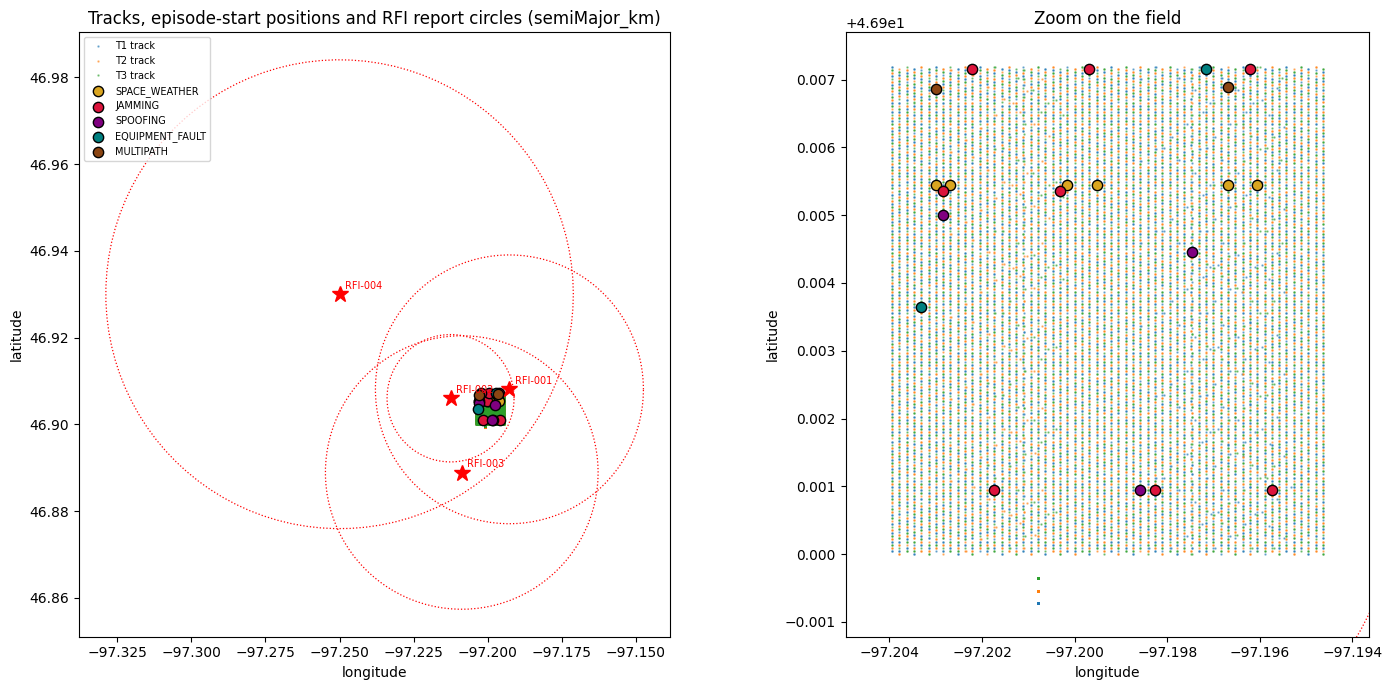

Field extent: 708 m east-west, 879 m north-south


,id,class,tractor,lat,lon
0,TRN-01,SPACE_WEATHER,T1,46.905440,-97.200158
1,TRN-01,SPACE_WEATHER,T2,46.905439,-97.196687
2,TRN-01,SPACE_WEATHER,T3,46.905440,-97.202682
3,TRN-02,SPACE_WEATHER,T1,46.905440,-97.202998
4,TRN-02,SPACE_WEATHER,T2,46.905439,-97.199527
5,TRN-02,SPACE_WEATHER,T3,46.905440,-97.196056
6,TRN-03,JAMMING,T1,46.900940,-97.195740
7,TRN-03,JAMMING,T2,46.900940,-97.201736
8,TRN-03,JAMMING,T3,46.900940,-97.198265
9,TRN-04,JAMMING,T1,46.905359,-97.200316


Multipath onsets TRN-11 (T3) and TRN-12 (T1) are 479 m apart


In [12]:
lat0 = tel.lat.mean()
km_lon = 111.32 * np.cos(np.radians(lat0))
onset = pd.DataFrame([{"id": e["id"], "class": e["class"], "tractor": t, "lat": by[t].loc[e["s"], "lat"], "lon": by[t].loc[e["s"], "lon"]}
                      for e in eps for t in e["trs"]])
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, zoom in zip(ax, (False, True)):
    for t in TR:
        g = by[t].iloc[::30]
        a.plot(g.lon, g.lat, ".", ms=1.5, color=TCOL[t], alpha=0.5, label=f"{t} track")
    for cls in CLASSES:
        o = onset[onset["class"] == cls]
        a.scatter(o.lon, o.lat, color=COLOR[cls], s=55, edgecolor="k", label=cls, zorder=3)
    for r in rfi.itertuples():
        a.plot(r.centerLon, r.centerLat, "*", color="red", ms=12, zorder=4)
        th = np.linspace(0, 2 * np.pi, 100)
        a.plot(r.centerLon + r.semiMajor_km / km_lon * np.cos(th), r.centerLat + r.semiMajor_km / 111.0 * np.sin(th), "r:", lw=0.9)
        a.annotate(r.id, (r.centerLon, r.centerLat), fontsize=7, color="red", xytext=(4, 4), textcoords="offset points")
    a.set_aspect(1 / np.cos(np.radians(lat0))); a.set_xlabel("longitude"); a.set_ylabel("latitude")
    if zoom:
        a.set_xlim(tel.lon.min() - 0.001, tel.lon.max() + 0.001); a.set_ylim(tel.lat.min() - 0.0005, tel.lat.max() + 0.0005)
        a.set_title("Zoom on the field")
    else:
        a.set_title("Tracks, episode-start positions and RFI report circles (semiMajor_km)")
ax[0].legend(fontsize=7, loc="upper left")
fig.tight_layout(); plt.show()

print(f"Field extent: {(tel.lon.max() - tel.lon.min()) * km_lon * 1000:.0f} m east-west, {(tel.lat.max() - tel.lat.min()) * 111_000:.0f} m north-south")
display(onset.round(6))
mp = onset[onset["class"] == "MULTIPATH"].reset_index(drop=True)
for i, j in combinations(range(len(mp)), 2):
    d = haversine_km(mp.lat[i], mp.lon[i], mp.lat[j], mp.lon[j]) * 1000
    print(f"Multipath onsets {mp.id[i]} ({mp.tractor[i]}) and {mp.id[j]} ({mp.tractor[j]}) are {d:.0f} m apart")

## 5. SDA context: nearest value vs min / max

Kp is 3-hourly, Dst hourly and S4 15-minute, held until the next sample, so "nearest" can miss a spike. For each episode:
the value in effect at onset, the min / max from 60 min before onset to 60 min after the end (including the sample in
effect at the start of that window), and the max Kp in the 6 h *before* onset, since Kp can lead farm impact while S4
lags it. `advisories_24h` lists advisory types issued in the 24 h up to the episode end.

In [13]:
CTX = pd.Timedelta("60min")


def span(df, col, a, b):
    """Values in [a, b], including the sample that was in effect at a."""
    prior = df.loc[df.ts <= a, "ts"]
    start = prior.max() if len(prior) else a
    return df.loc[(df.ts >= start) & (df.ts <= b), col]


rows = []
for e in eps:
    r = {"id": e["id"], "class": e["class"], "dur": fmt_dur(e["dur_s"])}
    for n, f in (("kp", kp), ("dst", dst), ("s4", s4)):
        w = span(f, n, e["s"] - CTX, e["e"] + CTX)
        r[f"{n}_near"], r[f"{n}_min"], r[f"{n}_max"] = near(f, n, e["s"]), w.min(), w.max()
    r["kp_max_prev6h"] = span(kp, "kp", e["s"] - pd.Timedelta("6h"), e["s"]).max()
    r["advisories_24h"] = ",".join(adv.loc[(adv.ts >= e["e"] - pd.Timedelta("24h")) & (adv.ts <= e["e"]), "type"])
    rows.append(r)
ctx = pd.DataFrame(rows)
display(ctx.round(2))
display(ctx.groupby("class").mean(numeric_only=True).round(2))
print("Overall feed range (min, mean, max):", {n: tuple(round(float(v), 2) for v in (f[n].min(), f[n].mean(), f[n].max())) for n, f in (("kp", kp), ("dst", dst), ("s4", s4))})
print("Advisories:"); display(adv)

,id,class,dur,kp_near,kp_min,kp_max,dst_near,dst_min,dst_max,s4_near,s4_min,s4_max,kp_max_prev6h,advisories_24h
0,TRN-01,SPACE_WEATHER,5.0h,9.0,3.0,9.0,-300.0,-412.0,-46.0,0.65,0.04,0.80,8.3,SPACE_WEATHER
1,TRN-02,SPACE_WEATHER,3.0h,6.8,3.0,6.8,-193.0,-211.0,-141.0,0.42,0.02,0.47,9.0,SPACE_WEATHER
2,TRN-03,JAMMING,42m,2.3,1.9,2.3,-13.0,-20.0,-13.0,0.05,0.03,0.07,2.3,ROUTINE
3,TRN-04,JAMMING,36m,2.0,1.9,2.0,-15.0,-15.0,-11.0,0.07,0.03,0.08,2.3,ROUTINE
4,TRN-05,JAMMING,36m,3.0,3.0,6.8,-166.0,-193.0,-165.0,0.44,0.42,0.46,9.0,SPACE_WEATHER
5,TRN-06,SPOOFING,42m,0.9,0.9,0.9,-17.0,-17.0,-12.0,0.08,0.03,0.08,2.1,ROUTINE
6,TRN-07,SPOOFING,48m,0.9,0.9,2.0,-8.0,-15.0,-8.0,0.03,0.02,0.06,2.0,ROUTINE
7,TRN-08,SPOOFING,36m,3.0,3.0,6.8,-165.0,-166.0,-141.0,0.45,0.02,0.47,6.8,SPACE_WEATHER
8,TRN-09,EQUIPMENT_FAULT,2.0h,0.9,0.9,2.3,-12.0,-17.0,-8.0,0.06,0.03,0.08,2.1,ROUTINE
9,TRN-10,EQUIPMENT_FAULT,48m,1.4,0.9,1.4,-10.0,-11.0,-10.0,0.04,0.03,0.07,2.0,ROUTINE


,kp_near,kp_min,kp_max,dst_near,dst_min,dst_max,s4_near,s4_min,s4_max,kp_max_prev6h
class,,,,,,,,,,
EQUIPMENT_FAULT,1.15,0.90,1.85,-11.00,-14.0,-9.00,0.05,0.03,0.08,2.05
JAMMING,2.43,2.27,3.70,-64.67,-76.0,-63.00,0.19,0.16,0.20,4.53
MULTIPATH,4.55,3.85,4.55,-105.00,-114.0,-89.50,0.23,0.03,0.27,5.55
SPACE_WEATHER,7.90,3.00,7.90,-246.50,-311.5,-93.50,0.53,0.03,0.63,8.65
SPOOFING,1.60,1.60,3.23,-63.33,-66.0,-53.67,0.19,0.02,0.20,3.63


Overall feed range (min, mean, max): {'kp': (0.8, 3.14, 9.0), 'dst': (-412.0, -62.17, -4.0), 's4': (0.02, 0.15, 0.8)}
Advisories:


,id,ts,type,svn,text
0,ADV-2026-117,2026-05-04 08:00:00+00:00,ROUTINE,G14,GPS SVN G14 scheduled maintenance window; set unusable 0800-0930Z. No conste...
1,ADV-2026-118,2026-05-05 07:00:00+00:00,SPACE_WEATHER,None,Severe geomagnetic storming in progress (G4-G5). Degraded single- and dual-f...


## 6. Scan every telemetry column

For each numeric column (plus `fix_rank`, one 0/1 column per fix state, `link_down` and `cn0_gap` = mean - min C/N0), on each
episode's labelled tractors: baseline mean (30 min before), event mean, delta, and event standard deviation, averaged over the
labelled tractors. The long table is `scan`; the pivots show `delta` and `event_sd`. Baselines that overlap another episode
are not clean (see section 2), so prefer `event_mean` when comparing classes.

In [14]:
SCAN_COLS = ["lat", "lon", "speed_mps", "cross_track_error_m", "num_sats", "mean_cn0_dbhz", "min_cn0_dbhz", "cn0_gap",
             "fix_rank", *[f"fix={s}" for s in FIX_ORDER], "link_down"]
rows = []
for e in eps:
    for c in SCAN_COLS:
        b = [seg(t, e["s"] - PAD, e["s"])[c] for t in e["trs"]]
        v = [seg(t, e["s"], e["e"])[c] for t in e["trs"]]
        rows.append({"id": e["id"], "class": e["class"], "column": c, "baseline_mean": np.mean([x.mean() for x in b]),
                     "event_mean": np.mean([x.mean() for x in v]), "event_sd": np.mean([x.std() for x in v])})
scan = pd.DataFrame(rows)
scan["delta"] = scan["event_mean"] - scan["baseline_mean"]
print("delta = event mean - baseline mean")
display(scan.pivot_table(index=["class", "id"], columns="column", values="delta").reindex(columns=SCAN_COLS).loc[CLASSES].round(3))
print("event standard deviation")
display(scan.pivot_table(index=["class", "id"], columns="column", values="event_sd").reindex(columns=SCAN_COLS).loc[CLASSES].round(3))

delta = event mean - baseline mean


column                    lat    lon  speed_mps  cross_track_error_m  num_sats  mean_cn0_dbhz  min_cn0_dbhz  cn0_gap  fix_rank  fix=RTK_FIXED  fix=RTK_FLOAT  fix=DGPS  fix=AUTONOMOUS  fix=NO_FIX  link_down
class           id                                                                                                                                                                                           
SPACE_WEATHER   TRN-01  0.004  0.002        4.5                1.014     0.002         -0.600        -1.112    0.511     0.029          0.000          0.002    -0.033           0.031       0.000      0.000
                TRN-02  0.000 -0.000        0.0                1.070    -1.743        -12.579       -15.491    2.911     1.498         -0.996          0.751     0.048           0.137       0.060      0.000
JAMMING         TRN-03  0.000  0.001        0.0                1.884    -5.434        -17.414       -20.026    2.613     2.335         -1.000          0.140     0.500           0.247       0.114      0.000
                TRN-04 -0.000  0.000        0.0                0.092    -0.854         -6.807        -7.858    1.051     0.409         -0.409          0.408     0.001           0.000       0.000      0.000
                TRN-05 -0.000  0.001        0.0                3.601    -3.676        -12.532       -14.442    1.910     2.237         -0.004         -0.946    -0.033           0.683       0.300      0.000
SPOOFING        TRN-06 -0.000 -0.001        0.0                3.345     0.029         -0.009        -0.127    0.118     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-07  0.000  0.002        0.0                6.716    -0.002         -0.006        -0.001   -0.005     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-08 -0.000  0.002        0.0                1.960     0.160          1.448         1.804   -0.355    -0.153          0.166         -0.179     0.013           0.000       0.000      0.000
EQUIPMENT_FAULT TRN-09 -0.000 -0.001        0.0                1.171    -0.476         -0.787        -3.758    2.971     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-10  0.000 -0.003        0.0                0.069     0.004         -0.001         0.016   -0.017     0.301         -0.301          0.301     0.000           0.000       0.000      0.301
MULTIPATH       TRN-11  0.003  0.001        0.0                0.100    -0.166         -0.180        -6.852    6.672     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-12  0.003 -0.002        0.0                0.234    -0.763         -9.403       -20.383   10.980     0.922         -0.922          0.923    -0.001           0.000       0.000      0.000

event standard deviation


column                    lat    lon  speed_mps  cross_track_error_m  num_sats  mean_cn0_dbhz  min_cn0_dbhz  cn0_gap  fix_rank  fix=RTK_FIXED  fix=RTK_FLOAT  fix=DGPS  fix=AUTONOMOUS  fix=NO_FIX  link_down
class           id                                                                                                                                                                                           
SPACE_WEATHER   TRN-01  0.002  0.003        0.0                0.871     0.816          1.531         2.370    2.181     0.218          0.000          0.117     0.214           0.182       0.000      0.000
                TRN-02  0.002  0.003        0.0                2.183     1.818          5.222         6.154    2.289     0.944          0.062          0.432     0.215           0.343       0.237      0.000
JAMMING         TRN-03  0.002  0.002        0.0                2.322     1.746          4.221         5.065    1.966     0.677          0.000          0.226     0.358           0.323       0.249      0.000
                TRN-04  0.002  0.001        0.0                0.135     1.263          1.420         2.079    1.896     0.376          0.374          0.375     0.019           0.000       0.000      0.000
                TRN-05  0.002  0.001        0.0                3.561     1.730          2.543         2.779    2.112     0.487          0.000          0.000     0.129           0.465       0.458      0.000
SPOOFING        TRN-06  0.002  0.001        0.0                2.139     1.244          1.631         7.534    6.150     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-07  0.002  0.001        0.0                4.274     0.807          0.586         1.945    1.870     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-08  0.002  0.001        0.0                1.422     0.890          3.996         5.205    2.312     0.470          0.375          0.422     0.243           0.000       0.000      0.000
EQUIPMENT_FAULT TRN-09  0.002  0.003        0.0                2.037     1.227          1.640         7.464    6.070     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-10  0.002  0.001        0.0                0.148     0.811          0.615         1.990    1.885     0.459          0.459          0.459     0.000           0.000       0.000      0.459
MULTIPATH       TRN-11  0.000  0.000        0.0                0.076     0.809          0.506         1.813    1.759     0.000          0.000          0.000     0.000           0.000       0.000      0.000
                TRN-12  0.000  0.000        0.0                0.160     0.752          1.300         2.321    2.366     0.243          0.243          0.243     0.000           0.000       0.000      0.000

### Space weather vs jamming, column by column

Event mean per episode for each column (plus episode duration and number of labelled tractors), the gap between the two
class means in pooled standard deviations, and whether the values split perfectly. With few episodes per class a
pure-noise feature splits perfectly by chance surprisingly often (`chance_of_perfect_split` below), so only trust a separator
when the gap is large **and** it makes physical sense.

In [15]:
SW, JAM = "SPACE_WEATHER", "JAMMING"
ev = scan.pivot_table(index="id", columns="column", values="event_mean")
ev["duration_min"] = pd.Series({e["id"]: e["min"] for e in eps})
ev["n_tractors"] = pd.Series({e["id"]: len(e["trs"]) for e in eps})
cls = pd.Series({e["id"]: e["class"] for e in eps})
a, b = ev[cls == SW], ev[cls == JAM]
from math import comb
print(f"{len(a)} space-weather vs {len(b)} jamming episodes -> chance of a perfect split for a noise feature = "
      f"{2 / comb(len(a) + len(b), len(a)):.0%}")
rows = []
for c in ev.columns:
    va, vb = a[c].to_numpy(), b[c].to_numpy()
    diff = abs(va.mean() - vb.mean())
    pooled = np.sqrt((va.var(ddof=1) + vb.var(ddof=1)) / 2) if len(va) > 1 and len(vb) > 1 else np.nan
    rows.append({"feature": c, "SW": np.round(va, 3).tolist(), "JAM": np.round(vb, 3).tolist(),
                 "gap_pooled_sd": 0.0 if diff == 0 else (diff / pooled if pooled and pooled > 0 else np.inf),
                 "perfect_split": bool(va.max() < vb.min() or vb.max() < va.min())})
display(pd.DataFrame(rows).sort_values("gap_pooled_sd", ascending=False).reset_index(drop=True).round(2))

2 space-weather vs 3 jamming episodes -> chance of a perfect split for a noise feature = 20%


,feature,SW,JAM,gap_pooled_sd,perfect_split
0,duration_min,"[300.0, 180.0]","[42.0, 36.0, 36.0]",3.36,True
1,num_sats,"[9.999, 10.258]","[6.567, 11.128, 7.309]",1.03,False
2,fix=NO_FIX,"[0.0, 0.06]","[0.114, 0.0, 0.3]",0.97,False
3,fix=AUTONOMOUS,"[0.034, 0.137]","[0.247, 0.0, 0.683]",0.90,False
4,n_tractors,"[3, 3]","[3, 2, 3]",0.82,False
5,fix=RTK_FIXED,"[0.0, 0.004]","[0.0, 0.591, 0.0]",0.81,False
6,cross_track_error_m,"[1.014, 1.091]","[1.905, 0.112, 3.88]",0.69,False
7,fix=DGPS,"[0.952, 0.048]","[0.5, 0.001, 0.017]",0.66,False
8,cn0_gap,"[9.071, 8.141]","[7.856, 6.4, 9.666]",0.51,False
9,fix=RTK_FLOAT,"[0.014, 0.751]","[0.14, 0.408, 0.0]",0.50,False


## 7. Edge timing

How abrupt are onsets and recoveries, and which signal moves first? For each episode, labelled tractor and signal, with the
level before and inside the episode (medians) and a 3 s smoothing, the time the signal crosses 10 %, 50 % and 90 % of the
step (sustained for 10 s). Signals with no clear step (smaller than 3 noise sigmas or a minimum size) are skipped.
`onset_s` is the 50 % crossing relative to the labelled start (negative = before the label); `rise_s` is the 10-90 % time;
`recover_s` is the 50 % crossing back, relative to the labelled end (the "after" level is the median of the next 10 min,
which is not necessarily clear sky if another episode follows).

In [16]:
EDGE_MIN_STEP = {"mean_cn0_dbhz": 2.0, "min_cn0_dbhz": 3.0, "num_sats": 1.0, "cross_track_error_m": 0.5, "fix_rank": 0.5, "link_down": 0.3}
EDGE_SMOOTH, HOLD = "3s", 10


def first_sustained(frac, thr):
    hit = (frac >= thr).astype(float)
    ok = hit.rolling(HOLD).min().shift(-(HOLD - 1)) == 1.0      # this sample and the next HOLD-1 are all past the threshold
    return frac.index[ok.to_numpy().argmax()] if ok.any() else pd.NaT


def edge_one(tr, e, col, kind):
    x = by[tr][col]
    pre, inn, post = x.loc[e["s"] - PAD: e["s"] - SEC], x.loc[e["s"]: e["e"] - SEC], x.loc[e["e"]: e["e"] + pd.Timedelta("10min") - SEC]
    l0, l1, centre, ref = (pre.median(), inn.median(), e["s"], pre) if kind == "onset" else (inn.median(), post.median(), e["e"], post)
    step = l1 - l0
    if not np.isfinite(step) or abs(step) < max(3 * np.nan_to_num(ref.std()), EDGE_MIN_STEP[col]):
        return None
    w = pd.Timedelta("10min") if e["dur_s"] >= 1200 else pd.Timedelta("2min")
    frac = (x.loc[centre - w: centre + w].rolling(EDGE_SMOOTH, center=True).mean() - l0) / step
    t10, t50, t90 = (first_sustained(frac, q) for q in (0.1, 0.5, 0.9))
    f = lambda t: (t - centre).total_seconds() if pd.notna(t) else np.nan
    return {"t50_s": f(t50), "rise_s": (t90 - t10).total_seconds() if pd.notna(t10) and pd.notna(t90) else np.nan, "level_before": l0, "level_after": l1}


rows = []
for e in eps:
    for t in e["trs"]:
        for col in EDGE_MIN_STEP:
            for kind in ("onset", "recovery"):
                r = edge_one(t, e, col, kind)
                if r:
                    rows.append({"id": e["id"], "class": e["class"], "tractor": t, "signal": col.replace("_dbhz", "").replace("_error_m", ""), "kind": kind, **r})
edges = pd.DataFrame(rows)
for kind, val in (("onset", "t50_s"), ("onset", "rise_s"), ("recovery", "t50_s")):
    name = {"t50_s": "onset_s" if kind == "onset" else "recover_s", "rise_s": "rise_s"}[val]
    print(f"{name} (median over the labelled tractors; blank = no clear step in that signal)")
    p = edges[edges.kind == kind].pivot_table(index=["class", "id"], columns="signal", values=val, aggfunc="median")
    display(p.reindex([c for c in CLASSES if c in p.index.get_level_values(0)], level=0).round(1))
first = (edges[(edges.kind == "onset") & edges.t50_s.notna()].groupby("id")
         .apply(lambda g: g.loc[g.t50_s.idxmin(), "signal"], include_groups=False))
print("Signal whose onset crossing comes first, per episode:", first.to_dict())

onset_s (median over the labelled tractors; blank = no clear step in that signal)


signal                cross_track  fix_rank  mean_cn0  min_cn0  num_sats
class         id                                                        
SPACE_WEATHER TRN-01          0.0       NaN       NaN      NaN       NaN
              TRN-02          NaN       0.0       0.0   -319.0       NaN
JAMMING       TRN-03          6.0       0.0       0.0      0.0       0.0
              TRN-04          NaN       1.0       0.0   -409.0       NaN
              TRN-05         28.0       0.0       0.0     -1.0       0.0
MULTIPATH     TRN-11          NaN       NaN       NaN      0.0       NaN
              TRN-12          NaN     -35.0     -35.0    -34.0       NaN

rise_s (median over the labelled tractors; blank = no clear step in that signal)


signal                cross_track  fix_rank  mean_cn0  min_cn0  num_sats
class         id                                                        
SPACE_WEATHER TRN-01         14.0       NaN       NaN      NaN       NaN
              TRN-02          NaN       2.0      11.0    353.0       NaN
JAMMING       TRN-03        565.0      21.0      20.0    588.0       4.0
              TRN-04          NaN       2.0       2.0    210.5       NaN
              TRN-05        112.0       2.0      71.0    445.0     636.0
MULTIPATH     TRN-12          NaN       1.0      12.0      NaN       NaN

recover_s (median over the labelled tractors; blank = no clear step in that signal)


signal                cross_track  fix_rank  mean_cn0  min_cn0  num_sats
class         id                                                        
SPACE_WEATHER TRN-01          1.0       0.0       0.0      0.0       NaN
              TRN-02          NaN       0.0       0.0      0.0       NaN
JAMMING       TRN-03         -1.0       0.0       0.0      0.0       0.0
              TRN-04          NaN    -470.0       0.0      0.0       NaN
              TRN-05          1.0       0.0      -1.0     -1.0       0.0
SPOOFING      TRN-06          1.0       NaN       NaN      NaN       NaN
              TRN-07          1.0       NaN       NaN      NaN       NaN
              TRN-08          1.0    -360.0    -360.0   -360.0       NaN
MULTIPATH     TRN-11          NaN       NaN       NaN   -120.0       NaN
              TRN-12          NaN       NaN       NaN   -120.0       NaN

Signal whose onset crossing comes first, per episode: {'TRN-01': 'cross_track', 'TRN-02': 'min_cn0', 'TRN-03': 'cross_track', 'TRN-04': 'min_cn0', 'TRN-05': 'min_cn0', 'TRN-11': 'min_cn0', 'TRN-12': 'mean_cn0'}


## 8. Unlabelled event detection

Three simple channels per tractor over the **whole dataset**, evaluated on moving rows only (parked reception is not
scored and is noisy): smoothed mean C/N0 below `LOW_DB`, smoothed cross-track error above `XTE_HI`, and the correction
link down for at least `LINK_FRAC` of a smoothing window. Hits closer than `MERGE_GAP` merge, intervals under `MIN_DUR` are
dropped, and same-channel intervals that overlap across tractors are grouped into one **event** with a tractor set.
`labelled` names the labelled episode(s) that overlap an event on a shared tractor; events matching none are
`UNLABELLED` (the evaluation window is where the unlabelled test episodes are).

In [17]:
LOW_DB, XTE_HI, LINK_FRAC = 30, 1.0, 0.2
SMOOTH, MIN_DUR, MERGE_GAP = "30s", pd.Timedelta("2min"), pd.Timedelta("30s")


def runs(mask):
    m = mask.fillna(False).to_numpy().astype(bool)
    if not m.any():
        return []
    edge = np.flatnonzero(np.diff(np.r_[False, m, False].astype(int)))
    idx = mask.index
    return [(idx[a], idx[b - 1] + SEC) for a, b in zip(edge[::2], edge[1::2])]


def channel_masks(t):
    x = by[t]
    roll = lambda c: x[c].rolling(SMOOTH, center=True).mean()
    return {"cn0_low": (roll("mean_cn0_dbhz") < LOW_DB) & x.moving,
            "xte_high": (roll("cross_track_error_m") > XTE_HI) & x.moving,
            "link_down": (roll("link_down") >= LINK_FRAC) & x.moving}


rows = []
for t in TR:
    for ch, mask in channel_masks(t).items():
        merged = []
        for a, b in runs(mask):
            if merged and a - merged[-1][1] <= MERGE_GAP:
                merged[-1][1] = b
            else:
                merged.append([a, b])
        rows += [{"channel": ch, "tractor": t, "start": a, "end": b} for a, b in merged if b - a >= MIN_DUR]
iv = pd.DataFrame(rows).sort_values(["channel", "start", "tractor"]).reset_index(drop=True)

# group same-channel intervals that overlap across tractors into events
events = []
for ch, g in iv.groupby("channel"):
    cur = None
    for r in g.sort_values("start").itertuples():
        if cur and r.start <= cur["end"] + MERGE_GAP:
            cur["end"] = max(cur["end"], r.end); cur["tractors"].add(r.tractor)
        else:
            if cur:
                events.append(cur)
            cur = {"channel": ch, "start": r.start, "end": r.end, "tractors": {r.tractor}}
    if cur:
        events.append(cur)
det = pd.DataFrame(events).sort_values("start").reset_index(drop=True)
det["tractors"] = det["tractors"].map(lambda s: tuple(sorted(s)))
det["n_tractors"] = det["tractors"].map(len)
det["dur"] = (det["end"] - det["start"]).dt.total_seconds().map(fmt_dur)
det["dur_min"] = (det["end"] - det["start"]).dt.total_seconds() / 60
det["labelled"] = [",".join(e["id"] for e in eps if e["s"] < r.end and r.start < e["e"] and set(e["trs"]) & set(r.tractors)) or "UNLABELLED"
                   for r in det.itertuples()]
det["window"] = np.where(det["start"] >= EVAL_START, "eval", "dev")
display(det.drop(columns="dur_min"))
print(f"{len(det)} events | matching a label: {(det.labelled != 'UNLABELLED').sum()} | UNLABELLED: {(det.labelled == 'UNLABELLED').sum()} "
      f"(dev {int(((det.labelled == 'UNLABELLED') & (det.window == 'dev')).sum())}, eval {int(((det.labelled == 'UNLABELLED') & (det.window == 'eval')).sum())}) "
      f"| on more than one tractor: {int((det.n_tractors > 1).sum())}")

print("Which channels see each labelled episode (on a labelled tractor)?")
cov_rows = []
for e in eps:
    hit = iv[(iv.start < e["e"]) & (e["s"] < iv.end) & iv.tractor.isin(e["trs"])]
    cov_rows.append({"id": e["id"], "class": e["class"], "dur": fmt_dur(e["dur_s"]), "tractors": ",".join(e["trs"]),
                     "channels": ",".join(sorted(hit.channel.unique())) or "MISSED",
                     "coverage": max([(min(r.end, e["e"]) - max(r.start, e["s"])).total_seconds() / e["dur_s"] for r in hit.itertuples()], default=0.0)})
display(pd.DataFrame(cov_rows).round(2))

,channel,start,end,tractors,n_tractors,dur,labelled,window
0,xte_high,2026-05-04 13:18:58+00:00,2026-05-04 13:54:10+00:00,"(T2,)",1,35m,"TRN-06,TRN-09",dev
1,xte_high,2026-05-04 16:30:00+00:00,2026-05-04 17:12:02+00:00,"(T1, T2, T3)",3,42m,TRN-03,dev
2,cn0_low,2026-05-04 16:30:08+00:00,2026-05-04 17:11:52+00:00,"(T1, T2, T3)",3,42m,TRN-03,dev
3,xte_high,2026-05-05 00:34:01+00:00,2026-05-05 01:18:12+00:00,"(T1,)",1,44m,TRN-07,dev
4,link_down,2026-05-05 02:19:17+00:00,2026-05-05 02:21:20+00:00,"(T1,)",1,2m,TRN-10,dev
5,link_down,2026-05-05 02:34:52+00:00,2026-05-05 02:36:58+00:00,"(T1,)",1,2m,TRN-10,dev
6,link_down,2026-05-05 02:42:37+00:00,2026-05-05 02:44:37+00:00,"(T1,)",1,2m,TRN-10,dev
7,xte_high,2026-05-05 11:00:17+00:00,2026-05-05 11:02:41+00:00,"(T1,)",1,2m,TRN-01,dev
8,xte_high,2026-05-05 11:06:02+00:00,2026-05-05 11:08:17+00:00,"(T3,)",1,2m,TRN-01,dev
9,xte_high,2026-05-05 11:28:22+00:00,2026-05-05 11:31:39+00:00,"(T2,)",1,3m,TRN-01,dev


49 events | matching a label: 32 | UNLABELLED: 17 (dev 0, eval 17) | on more than one tractor: 15
Which channels see each labelled episode (on a labelled tractor)?


,id,class,dur,tractors,channels,coverage
0,TRN-01,SPACE_WEATHER,5.0h,"T1,T2,T3","cn0_low,xte_high",0.60
1,TRN-02,SPACE_WEATHER,3.0h,"T1,T2,T3","cn0_low,xte_high",0.20
2,TRN-03,JAMMING,42m,"T1,T2,T3","cn0_low,xte_high",0.99
3,TRN-04,JAMMING,36m,"T1,T3",MISSED,0.00
4,TRN-05,JAMMING,36m,"T1,T2,T3","cn0_low,xte_high",1.00
5,TRN-06,SPOOFING,42m,T2,xte_high,0.83
6,TRN-07,SPOOFING,48m,T1,xte_high,0.92
7,TRN-08,SPOOFING,36m,T3,xte_high,0.75
8,TRN-09,EQUIPMENT_FAULT,2.0h,T2,xte_high,0.29
9,TRN-10,EQUIPMENT_FAULT,48m,T1,link_down,0.04


## 9. Rule classifier and score

Rules are applied in order:

1. speed < 1 m/s or NO_FIX for more than half the samples -> `EQUIPMENT_FAULT`
2. cross-track error > 3 m -> `SPOOFING`
3. two or more tractors hit at once -> `SPACE_WEATHER`
4. <= 15.5 min -> `MULTIPATH`
5. >= 20.5 min -> `JAMMING`
6. <= 19.5 min -> `SPACE_WEATHER`
7. otherwise -> `AMBIGUOUS` (jamming or space weather)

Speed and cross-track error use the median over the episode. These thresholds were chosen for the earlier generated fixture
and are kept here exactly as given so the notebook shows how they fare on the real labels; edit the constants to iterate.
"Tractors hit" is the clear-sky C/N0 count from section 2 on the labelled set, and the event's tractor count on detected events.

**Scoring** follows the event guide: detections and truth match one-to-one, requiring temporal IoU >= 0.30 and
tractor-set IoU >= 0.50; same-class matches take priority, then the number of matches, then total overlap. Score =
25 x macro-F1 over the five classes + 15 x mean onset credit (full within 5 min, linear to zero at 60 min, zero for a wrong
class), out of 40. Extra detections count as false positives, except unmatched multipath of at most 3 min that overlaps no
true multipath. The match is solved exactly (no scipy needed). This is a local re-implementation of the published rules, not
the organizers' code.

In [18]:
SPEED_MIN, CTE_MAX, NOFIX_FRAC = 1.0, 3.0, 0.5
MULTIPATH_MAX, JAMMING_MIN, SW_MAX = 15.5, 20.5, 19.5
AMBIGUOUS_AS = None          # None = an ambiguous prediction is dropped (a miss); or set "JAMMING" / "SPACE_WEATHER" to force a guess


def classify(speed_median, no_fix_frac, cte_median, n_tractors, minutes):
    if speed_median < SPEED_MIN or no_fix_frac > NOFIX_FRAC:
        return "EQUIPMENT_FAULT"
    if cte_median > CTE_MAX:
        return "SPOOFING"
    if n_tractors >= 2:
        return "SPACE_WEATHER"
    if minutes <= MULTIPATH_MAX:
        return "MULTIPATH"
    if minutes >= JAMMING_MIN:
        return "JAMMING"
    if minutes <= SW_MAX:
        return "SPACE_WEATHER"
    return "AMBIGUOUS"


def seg_features(trs, a, b):
    s_ = pd.concat([seg(t, a, b) for t in trs])
    return s_.speed_mps.median(), (s_.fix_state == "NO_FIX").mean(), s_.cross_track_error_m.median()


# ---- scoring (the published rules) -----------------------------------------------------------------------------------
def _tiou(p, q):
    inter = max(0.0, (min(p[1], q[1]) - max(p[0], q[0])).total_seconds())
    union = (p[1] - p[0]).total_seconds() + (q[1] - q[0]).total_seconds() - inter
    return inter / union if union else (1.0 if p[0] == q[0] else 0.0), inter


def _siou(p, q):
    a, b = set(p[2]), set(q[2])
    return len(a & b) / len(a | b)


def score(truth, pred):
    """truth / pred: lists of (start, end, tractors, class). Returns the diagnostic score (out of 40) and its parts."""
    elig = {}
    for i, p in enumerate(truth):
        for j, q in enumerate(pred):
            ti, inter = _tiou(p, q)
            if ti >= 0.30 and _siou(p, q) >= 0.50:
                elig[(i, j)] = (ti, inter)

    @lru_cache(maxsize=None)
    def best(i, used):          # maximise (same-class matches, matches, overlap seconds), in that order
        if i == len(truth):
            return (0, 0, 0.0, ())
        top = best(i + 1, used)
        for (ti_, j), (_, inter) in elig.items():
            if ti_ != i or used >> j & 1:
                continue
            sub = best(i + 1, used | 1 << j)
            cand = (sub[0] + (truth[i][3] == pred[j][3]), sub[1] + 1, sub[2] + inter, ((i, j),) + sub[3])
            if cand[:3] > top[:3]:
                top = cand
        return top

    pairs = best(0, 0)[3]
    n = {c: {"tp": 0, "fp": 0, "fn": 0} for c in CLASS_LIST}
    matched_t, matched_p, credit, detail = set(), set(), 0.0, []
    for i, j in pairs:
        matched_t.add(i); matched_p.add(j)
        err = (pred[j][0] - truth[i][0]).total_seconds() / 60
        same = truth[i][3] == pred[j][3]
        oc = (1.0 if abs(err) <= 5 else max(0.0, (60 - abs(err)) / 55)) if same else 0.0
        credit += oc
        if same:
            n[truth[i][3]]["tp"] += 1
        else:
            n[truth[i][3]]["fn"] += 1; n[pred[j][3]]["fp"] += 1
        detail.append({"truth": f"{truth[i][3]} {truth[i][0]:%m-%d %H:%M:%S}", "pred": f"{pred[j][3]} {pred[j][0]:%m-%d %H:%M:%S}",
                       "time_iou": round(elig[(i, j)][0], 2), "onset_err_min": round(err, 1), "onset_credit": round(oc, 2)})
    for i, p in enumerate(truth):
        if i not in matched_t:
            n[p[3]]["fn"] += 1
            detail.append({"truth": f"{p[3]} {p[0]:%m-%d %H:%M:%S}", "pred": "(missed)", "time_iou": np.nan, "onset_err_min": np.nan, "onset_credit": 0.0})
    exempt = 0
    for j, q in enumerate(pred):
        if j in matched_p:
            continue
        short_mp = q[3] == "MULTIPATH" and (q[1] - q[0]).total_seconds() <= 180 and not any(
            p[3] == "MULTIPATH" and _tiou(p, q)[1] > 0 for p in truth)
        if short_mp:
            exempt += 1
        else:
            n[q[3]]["fp"] += 1
        detail.append({"truth": "(none)", "pred": f"{q[3]} {q[0]:%m-%d %H:%M:%S}" + (" [exempt]" if short_mp else ""), "time_iou": np.nan,
                       "onset_err_min": np.nan, "onset_credit": 0.0})
    f1 = {c: (2 * v["tp"] / (2 * v["tp"] + v["fp"] + v["fn"]) if v["tp"] else 0.0) for c, v in n.items()}
    macro, onset_c = sum(f1.values()) / len(CLASS_LIST), (credit / len(truth) if truth else 0.0)
    return {"score": 25 * macro + 15 * onset_c, "macro_f1": macro, "onset_credit": onset_c, "f1": f1, "counts": n, "detail": pd.DataFrame(detail), "exempt": exempt}


def to_pred(rows):
    out = []
    for s_, e_, t_, c_ in rows:
        c_ = AMBIGUOUS_AS if c_ == "AMBIGUOUS" else c_
        if c_:
            out.append((s_, e_, tuple(t_), c_))
    return out


def report(res, label):
    print(f"{label}: score {res['score']:.2f} / 40 | macro-F1 {res['macro_f1']:.3f} | mean onset credit {res['onset_credit']:.3f}")
    print("  F1 by class:", {k: round(v, 2) for k, v in res["f1"].items()}, "| TP/FP/FN:", {k: tuple(v.values()) for k, v in res["counts"].items()})


# ---- labelled set, classified from the labelled windows and tractors (tests the class rules, not detection) ---------
lab = []
for e in eps:
    sp, nf, ct = seg_features(e["trs"], e["s"], e["e"])
    n_hit = int(fleet.loc[e["i"], "n_hit"])
    lab.append({"id": e["id"], "truth": e["class"], "tractors": ",".join(e["trs"]), "min": round(e["min"], 1), "speed_median": sp, "no_fix_frac": nf,
                "cte_median": ct, "n_hit": n_hit, "pred": classify(sp, nf, ct, n_hit, e["min"])})
lab = pd.DataFrame(lab)
display(lab.round(2))
display(pd.crosstab(lab["truth"], lab["pred"], margins=True))
truth = [(e["s"], e["e"], tuple(e["trs"]), e["class"]) for e in eps]
res_lab = score(truth, to_pred([(e["s"], e["e"], e["trs"], p) for e, p in zip(eps, lab["pred"])]))
print(f"Accuracy {(lab.truth == lab.pred).mean():.0%} ({(lab.pred == 'AMBIGUOUS').sum()} ambiguous)")
report(res_lab, "Labelled windows + labelled tractors")
display(res_lab["detail"])

,id,truth,tractors,min,speed_median,no_fix_frac,cte_median,n_hit,pred
0,TRN-01,SPACE_WEATHER,"T1,T2,T3",300.0,4.5,0.00,0.83,3,SPACE_WEATHER
1,TRN-02,SPACE_WEATHER,"T1,T2,T3",180.0,4.5,0.06,0.30,3,SPACE_WEATHER
2,TRN-03,JAMMING,"T1,T2,T3",42.0,4.5,0.11,0.99,3,SPACE_WEATHER
3,TRN-04,JAMMING,"T1,T3",36.0,4.5,0.00,0.03,2,SPACE_WEATHER
4,TRN-05,JAMMING,"T1,T2,T3",36.0,4.5,0.30,2.89,3,SPACE_WEATHER
5,TRN-06,SPOOFING,T2,42.0,4.5,0.00,2.99,0,JAMMING
6,TRN-07,SPOOFING,T1,48.0,4.5,0.00,6.00,0,SPOOFING
7,TRN-08,SPOOFING,T3,36.0,4.5,0.00,2.00,3,SPACE_WEATHER
8,TRN-09,EQUIPMENT_FAULT,T2,120.0,4.5,0.00,0.03,0,JAMMING
9,TRN-10,EQUIPMENT_FAULT,T1,48.0,4.5,0.00,0.02,0,JAMMING


pred,JAMMING,MULTIPATH,SPACE_WEATHER,SPOOFING,All
truth,,,,,
EQUIPMENT_FAULT,2,0,0,0,2
JAMMING,0,0,3,0,3
MULTIPATH,0,1,1,0,2
SPACE_WEATHER,0,0,2,0,2
SPOOFING,1,0,1,1,3
All,3,1,7,1,12


Accuracy 33% (0 ambiguous)
Labelled windows + labelled tractors: score 13.06 / 40 | macro-F1 0.322 | mean onset credit 0.333
  F1 by class: {'SPACE_WEATHER': 0.44, 'JAMMING': 0.0, 'SPOOFING': 0.5, 'EQUIPMENT_FAULT': 0.0, 'MULTIPATH': 0.67} | TP/FP/FN: {'SPACE_WEATHER': (2, 5, 0), 'JAMMING': (0, 3, 3), 'SPOOFING': (1, 0, 2), 'EQUIPMENT_FAULT': (0, 0, 2), 'MULTIPATH': (1, 0, 1)}


,truth,pred,time_iou,onset_err_min,onset_credit
0,SPACE_WEATHER 05-05 11:00:00,SPACE_WEATHER 05-05 11:00:00,1.0,0.0,1.0
1,SPACE_WEATHER 05-05 19:00:00,SPACE_WEATHER 05-05 19:00:00,1.0,0.0,1.0
2,JAMMING 05-04 16:30:00,SPACE_WEATHER 05-04 16:30:00,1.0,0.0,0.0
3,JAMMING 05-04 21:00:00,SPACE_WEATHER 05-04 21:00:00,1.0,0.0,0.0
4,JAMMING 05-05 20:00:00,SPACE_WEATHER 05-05 20:00:00,1.0,0.0,0.0
5,SPOOFING 05-04 13:12:00,JAMMING 05-04 13:12:00,1.0,0.0,0.0
6,SPOOFING 05-05 00:30:00,SPOOFING 05-05 00:30:00,1.0,0.0,1.0
7,SPOOFING 05-05 21:30:00,SPACE_WEATHER 05-05 21:30:00,1.0,0.0,0.0
8,EQUIPMENT_FAULT 05-04 12:00:00,JAMMING 05-04 12:00:00,1.0,0.0,0.0
9,EQUIPMENT_FAULT 05-05 02:00:00,JAMMING 05-05 02:00:00,1.0,0.0,0.0


### On the detected events

The same rules applied to the events from section 8 (duration, tractor set and features come from the detected event). Dev-window
events are scored against the dev labels exactly like a submission would be; events in the evaluation window are the
unlabelled set, so only their predicted classes are listed.

In [19]:
feat = [seg_features(list(r.tractors), r.start.ceil("s"), r.end.floor("s")) for r in det.itertuples()]
det["speed_median"], det["no_fix_frac"], det["cte_median"] = zip(*feat)
det["pred"] = [classify(r.speed_median, r.no_fix_frac, r.cte_median, r.n_tractors, r.dur_min) for r in det.itertuples()]
cols = ["window", "channel", "start", "dur", "tractors", "labelled", "speed_median", "no_fix_frac", "cte_median", "pred"]
display(det[cols].round(2))

dev = det[det.window == "dev"]
res_det = score(truth, to_pred([(r.start, r.end, r.tractors, r.pred) for r in dev.itertuples()]))
report(res_det, "Detected dev events vs dev labels")
display(res_det["detail"])
rest = det[det.window == "eval"]
print(f"Evaluation-window events ({len(rest)}): predicted classes {rest['pred'].value_counts().to_dict()}")

,window,channel,start,dur,tractors,labelled,speed_median,no_fix_frac,cte_median,pred
0,dev,xte_high,2026-05-04 13:18:58+00:00,35m,"(T2,)","TRN-06,TRN-09",4.5,0.00,3.50,SPOOFING
1,dev,xte_high,2026-05-04 16:30:00+00:00,42m,"(T1, T2, T3)",TRN-03,4.5,0.11,0.99,SPACE_WEATHER
2,dev,cn0_low,2026-05-04 16:30:08+00:00,42m,"(T1, T2, T3)",TRN-03,4.5,0.11,0.99,SPACE_WEATHER
3,dev,xte_high,2026-05-05 00:34:01+00:00,44m,"(T1,)",TRN-07,4.5,0.00,6.46,SPOOFING
4,dev,link_down,2026-05-05 02:19:17+00:00,2m,"(T1,)",TRN-10,4.5,0.00,0.05,MULTIPATH
5,dev,link_down,2026-05-05 02:34:52+00:00,2m,"(T1,)",TRN-10,4.5,0.00,0.05,MULTIPATH
6,dev,link_down,2026-05-05 02:42:37+00:00,2m,"(T1,)",TRN-10,4.5,0.00,0.07,MULTIPATH
7,dev,xte_high,2026-05-05 11:00:17+00:00,2m,"(T1,)",TRN-01,4.5,0.00,0.87,MULTIPATH
8,dev,xte_high,2026-05-05 11:06:02+00:00,2m,"(T3,)",TRN-01,4.5,0.00,0.92,MULTIPATH
9,dev,xte_high,2026-05-05 11:28:22+00:00,3m,"(T2,)",TRN-01,4.5,0.00,0.79,MULTIPATH


Detected dev events vs dev labels: score 7.04 / 40 | macro-F1 0.184 | mean onset credit 0.164
  F1 by class: {'SPACE_WEATHER': 0.12, 'JAMMING': 0.0, 'SPOOFING': 0.8, 'EQUIPMENT_FAULT': 0.0, 'MULTIPATH': 0.0} | TP/FP/FN: {'SPACE_WEATHER': (1, 14, 1), 'JAMMING': (0, 1, 3), 'SPOOFING': (2, 0, 1), 'EQUIPMENT_FAULT': (0, 0, 2), 'MULTIPATH': (0, 3, 2)}


,truth,pred,time_iou,onset_err_min,onset_credit
0,SPACE_WEATHER 05-05 11:00:00,SPACE_WEATHER 05-05 12:59:53,0.60,119.9,0.00
1,JAMMING 05-04 16:30:00,SPACE_WEATHER 05-04 16:30:00,1.00,0.0,0.00
2,JAMMING 05-05 20:00:00,SPACE_WEATHER 05-05 19:59:50,0.99,-0.2,0.00
3,SPOOFING 05-04 13:12:00,SPOOFING 05-04 13:18:58,0.83,7.0,0.96
4,SPOOFING 05-05 00:30:00,SPOOFING 05-05 00:34:01,0.91,4.0,1.00
5,SPOOFING 05-05 21:30:00,JAMMING 05-05 21:38:57,0.75,8.9,0.00
6,SPACE_WEATHER 05-05 19:00:00,(missed),NaN,NaN,0.00
7,JAMMING 05-04 21:00:00,(missed),NaN,NaN,0.00
8,EQUIPMENT_FAULT 05-04 12:00:00,(missed),NaN,NaN,0.00
9,EQUIPMENT_FAULT 05-05 02:00:00,(missed),NaN,NaN,0.00


Evaluation-window events (17): predicted classes {'MULTIPATH': 15, 'SPOOFING': 1, 'JAMMING': 1}
